# Process 분석: 세 기간 통합 로그와 실행 이상 후보


연구 주제: **대규모 로그 데이터 기반 비지도 학습 이상탐지 AI 모델 개발**

다음 세 기간의 실제 로그를 합쳐 분석합니다. 각 행에 `source_period`, `source_file`을
남겨 통합 분포와 기간별 차이를 함께 확인합니다.

| 기간 폴더 | 수집 범위 |
|---|---|
| `25년12월24일-26년4월6일` | 2025-12-24 ~ 2026-04-06 |
| `26년8월15일-26년9월14일` | 2026-08-15 ~ 2026-09-14 |
| `26년9월30일-26년10월2일` | 2026-09-30 ~ 2026-10-02 |

파일명과 확장자가 실제 내용과 다른 최근 기간은 **컬럼 구조**로 소스를 선택합니다.
트랜잭션은 `EC_MESSAGE_BODY.csv` 안의 SQL 트랜잭션 테이블,
프로세스는 `EC_TRANSACTION_MONITORING.csv` 안의 프로세스 CSV를 사용합니다.
메시지 로그인 `EC_PROCESS_MONITORING.csv`는 프로세스 분석에 섞지 않습니다.

시간대가 있는 시각은 한국 시간으로 변환하고, 시간대 없는 원본 시각은 한국 시간으로
해석합니다. 기간 사이의 공백과 관측되지 않은 시간 구간은 수집 여부를 알 수 없으므로
트래픽 0으로 채우지 않습니다. 통계적 이상치, 실패 상태, 정합성 위반은 검토 후보이며
실제 이상 여부를 확정하는 정답 라벨이 아닙니다.

실행 환경: Python 3.10+, pandas 2+, numpy, matplotlib, seaborn, scikit-learn 1.2+.
세 노트북과 `log_analysis_common.py`, `log_analysis_visuals.py`를 같은 `code/` 폴더에 둡니다.
전체 통계는 원본 전체를 사용하고, 그래프·PCA·모델 학습 표본만 크기를 제한합니다.
분석 표와 그래프는 노트북에서 확인하며 별도 결과 파일은 생성하지 않습니다.

### 그래프 읽는 순서

① 파란색 = 2025.12–2026.04, ② 초록색 = 2026.08–09,
③ 주황색 = 2026.09.30–10.02입니다. 빨간색은 점검 후보·비교 기준선입니다.
각 그림 아래 **실제 결과 → 의미 → 모델 개발에 반영**을 함께 읽습니다.
**전체 데이터**는 발생률·통계 계산, **균형 표본**은 분포·산점도 비교에 사용합니다.
기간별 표본 추출률은 첫 그래프에 명시합니다. 그림에서 일부 범위를 확대할 경우
화면 밖 행 수를 표시하며 모델 계산에서는 제외하지 않습니다.
실행한 그래프와 해석은 노트북 출력에 포함해 파일을 열면 바로 확인할 수 있습니다.

> 공개 저장소용 연구 스냅샷입니다. 원본·평가 데이터셋과 학습/검증 캐시, 행별 예측 배열은 포함하지 않습니다. 개별 원본 로그 미리보기 출력은 제거했습니다. 집계 표와 그림은 저장된 실험 결과이며, 원본 기반 분석을 재실행하려면 별도 데이터가 필요합니다.

## 1. 환경 설정과 세 기간 통합 로드

공통 로더는 대문자/소문자 컬럼명, CSV/SQL 형식, 결측치 표기를 통일합니다.
`responseCode`는 문자열로 유지하므로 성공 코드 `0000`의 앞자리 0이 사라지지 않습니다.
중복 내보내기 파일은 하나만 선택하고 분석 컬럼이 모두 같은 행만 제거합니다.
재시도 및 같은 키의 서로 다른 로그는 유지하고 감사 표에 집계합니다.

In [1]:
from pathlib import Path
import sys
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents]
            if (p / "code" / "log_analysis_common.py").exists() and (p / "data").is_dir())
if str(ROOT / "code") not in sys.path:
    sys.path.insert(0, str(ROOT / "code"))
from log_analysis_common import (
    PERIODS, load_logs, text, quality_table, numeric_summary, add_time_features,
    sample_by_period, time_summary, hourly_history_candidates, iqr_summary,
    contextual_duration, numeric_drift, categorical_drift, dependency_features,
    latest_transaction_state, transaction_process_summary, fit_anomaly_baseline,
    baseline_report, signed_log, setup_plotting,
)
from log_analysis_visuals import (
    plot_sampling, plot_missingness, plot_numeric_distributions, plot_categories,
    plot_period_timeseries, plot_hour_pattern, plot_traffic_candidates,
    plot_statistical_candidates, plot_drift, plot_correlation, plot_model_scores,
    plot_projection, plot_rule_rates, plot_dependency, plot_merge_counts,
    plot_merge_status, plot_merge_performance, plot_sequences, note,
)

DATA_DIR = ROOT / "data"
RANDOM_STATE = 42
PLOT_SAMPLE = 30_000
MAX_TRAIN_ROWS = 100_000
SCORE_BATCH_ROWS = 100_000
ALERT_QUANTILE = 0.99
setup_plotting()


In [ ]:
df, source_audit = load_logs("process", DATA_DIR)
display(source_audit)
print(f"원본 합계: {source_audit['raw_rows'].sum():,}건")
print(f"분석 합계: {len(df):,}건 / {df.shape[1]}개 컬럼")
print(f"메모리 사용량: {df.memory_usage(deep=True).sum() / 1024**2:,.1f} MiB")
display(df.head())


## 2. 스키마·결측·중복·관측 범위

파싱 실패, 중복 키, 결측 시간과 기간별 결측률을 먼저 확인합니다.
`observed_days`는 실제 로그가 존재하는 날짜 수로, 폴더명의 일수와 다를 수 있습니다.
짧은 구간의 부족한 로그나 누락 컬럼을 장애로 바로 해석하지 않습니다.

In [ ]:
display(quality_table(df))
missing_by_period = df.isna().groupby(df["source_period"], observed=True).mean().mul(100)
display(missing_by_period.round(2))
period_volume = source_audit.set_index("source_period")[["raw_rows", "rows", "observed_days"]].copy()
period_volume["share_pct"] = period_volume["rows"] / len(df) * 100
period_volume["rows_per_observed_day"] = period_volume["rows"] / period_volume["observed_days"]
display(period_volume.round(2))


### 2.1 전체 규모와 균형 표본은 다릅니다

왼쪽은 전체 행 수, 오른쪽은 원본과 시각화 표본의 기간 구성입니다.
표본은 기간별 최대 1만 행을 고정 시드로 추출합니다.
실제 장애 발생률이나 결측률은 이 표본이 아닌 전체 데이터에서 계산합니다.

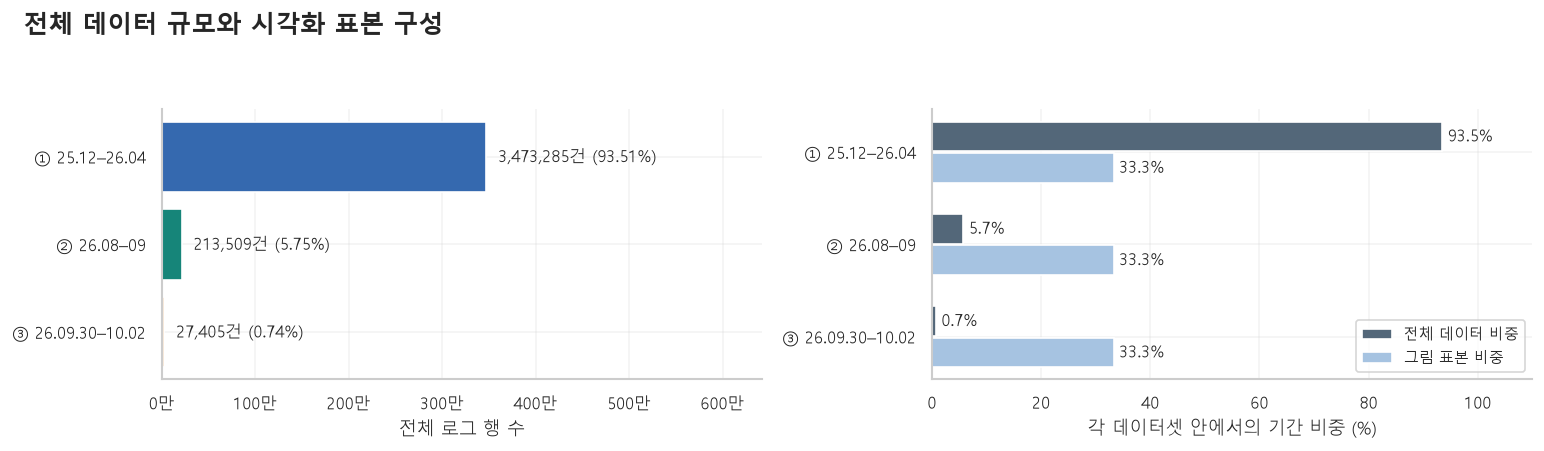

,전체 행 수,그림 표본 행 수,전체 내 비중 (%),표본 내 비중 (%),기간별 추출률 (%)
source_period,,,,,
① 25.12–26.04,3473285,10000,93.514,33.333,0.288
② 26.08–09,213509,10000,5.748,33.333,4.684
③ 26.09.30–10.02,27405,10000,0.738,33.333,36.490


**실제 결과**

- 전체 3,714,199건 중 ① 25.12–26.04가 93.51%입니다. 시각화는 30,000건을 기간별 균형 추출했습니다.

**의미**: 통합 건수 그래프는 가장 큰 기간의 특성을 주로 보여줍니다. 균형 표본은 짧은 기간을 비교하기 위한 것으로 전체 발생 비율을 대표하지 않습니다.

**모델 개발에 반영**: 전체 통계로 발생률을 계산하고, 기간별 표본으로 분포 형태를 비교합니다. 표본 추출률이 큰 최근 기간을 전체 비중으로 오해하지 않습니다.

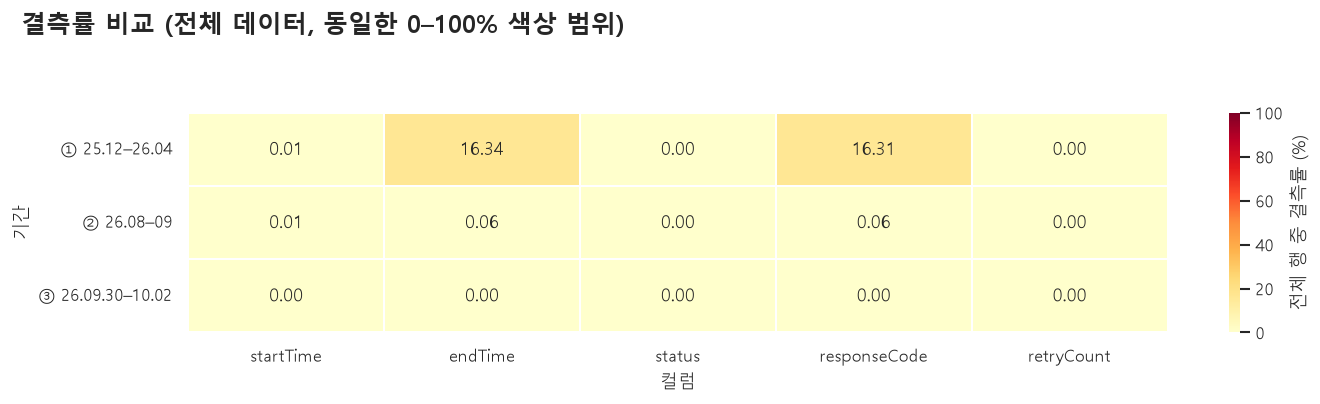

**실제 결과**

- ① 25.12–26.04: 종료시각 결측 567,442건 (16.34%).
- ② 26.08–09: 종료시각 결측 136건 (0.06%).
- ③ 26.09.30–10.02: 종료시각 결측 0건 (0.00%).

**의미**: 종료시각 결측은 처리시간을 계산할 수 없는 로그입니다. 미완료 상태·수집 누락을 구분해야 하며 처리시간 0으로 대치하면 분포가 왜곡됩니다.

**모델 개발에 반영**: 결측 여부 피처를 유지하고, 완료 로그 지연 탐지와 미완료 로그 탐지를 분리합니다. 0.00%는 반올림된 값일 수 있으므로 건수도 확인합니다.

In [4]:
plot_df = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)
sample_audit = plot_sampling(df, plot_df)
plot_missingness(df, ["startTime", "endTime", "status", "responseCode", "retryCount"])


분석 단위는 프로세스 **실행 로그/재시도 행**입니다. `processId`는 업무 템플릿에서
반복되는 식별자이므로 단독으로 실행을 식별하지 않습니다.
실행 키는 `source_period + transactionId + processId + retryCount`입니다.
`totalCount`/`successCount`/`errorCount`는 프로세스 수가 아니라 처리 데이터 건수입니다.

## 3. 처리시간과 수치 분포

처리시간은 `endTime - startTime`의 밀리초 값입니다. 음수·0·결측과
p95/p99/p99.9를 확인해 긴 꼬리와 불완전한 실행 로그를 구분합니다.
음수는 검증을 위해 유지합니다. 시간 분포는 실제 단위의 로그 눈금으로 읽고,
이산 카운트 값은 전체 행의 100% 구성 막대로 비교합니다.
모든 기간은 같은 히스토그램 구간과 세로축을 사용합니다.

In [5]:
add_time_features(df)
NUMERIC_COLS = ['duration_ms', 'totalCount', 'successCount', 'errorCount', 'retryCount']
display(numeric_summary(df, NUMERIC_COLS))
print(f"음수 처리시간: {df['negative_duration'].sum():,}건")
print(f"종료시각 없음: {df['missing_end'].sum():,}건")


,count,mean,std,min,1%,25%,50%,75%,95%,99%,99.9%,max,missing_pct,zero_pct,negative_count,skewness
duration_ms,3146616.0,2906.564,6527.784,0.0,16.0,391.0,619.0,5572.0,8699.0,9655.0,1.957938e+04,1802839.0,15.281,0.001,0,165.566
totalCount,3714194.0,210852.024,3699527.350,0.0,0.0,10000.0,10000.0,10000.0,10000.0,10485760.0,1.048576e+07,524288000.0,0.000,15.492,0,42.244
successCount,3714194.0,210743.218,3695323.879,0.0,0.0,10000.0,10000.0,10000.0,10000.0,10485760.0,1.048576e+07,524288000.0,0.000,18.852,0,42.244
errorCount,3714194.0,0.993,636.573,0.0,0.0,0.0,0.0,0.0,0.0,1.0,1.000000e+00,500000.0,0.000,96.640,0,782.852
retryCount,3714199.0,0.000,0.000,0.0,0.0,0.0,0.0,0.0,0.0,0.0,0.000000e+00,0.0,0.000,100.000,0,0.000


음수 처리시간: 0건
종료시각 없음: 567,578건


In [6]:
# duration_ms 등 파생 컬럼을 포함해 동일 시드로 표본을 다시 구성합니다.
plot_df = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)


### 수치 분포: `duration_ms`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

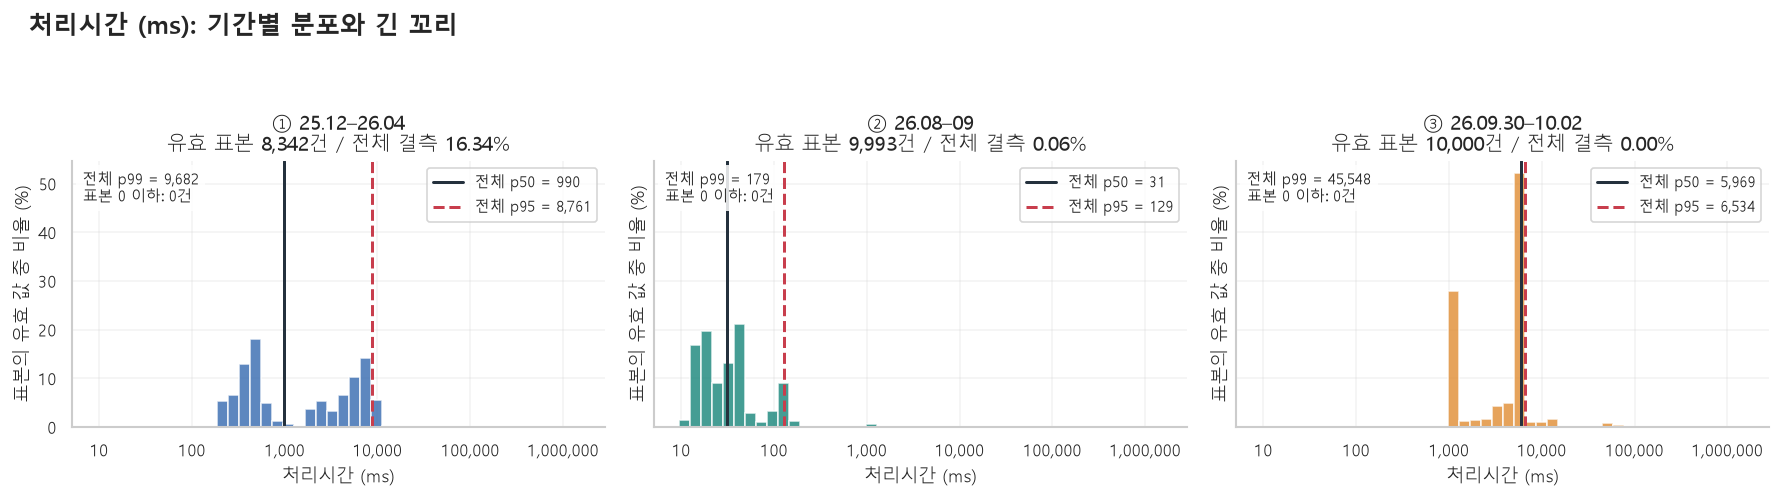

**실제 결과**

- ① 25.12–26.04: 전체 중앙값 990, p95 8,761, p99 9,682.
- ② 26.08–09: 전체 중앙값 31, p95 129, p99 179.
- ③ 26.09.30–10.02: 전체 중앙값 5,969, p95 6,534, p99 45,548.

**의미**: 가로축은 로그 간격이지만 눈금은 실제 단위입니다. 히스토그램은 같은 구간·같은 세로축을 사용하는 균형 표본이며 선과 분위수는 전체 데이터입니다. p95보다 큰 값은 전체 유효 값의 최대 약 5%입니다(동률 제외). 표본에 없는 극단값은 히스토그램 범위 밖일 수 있으며 전체 통계 표에서 확인합니다.

**모델 개발에 반영**: 절대 처리시간과 업무별 상대 지연을 함께 사용합니다. 중앙값 차이가 크면 기간·업무 그룹 기준선을 비교하고, 긴 꼬리에는 log1p 변환을 적용합니다. 음수·0·결측은 별도 정합성 점검 대상입니다.

In [7]:
plot_numeric_distributions(df, plot_df, ['duration_ms'])


### 수치 분포: `totalCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

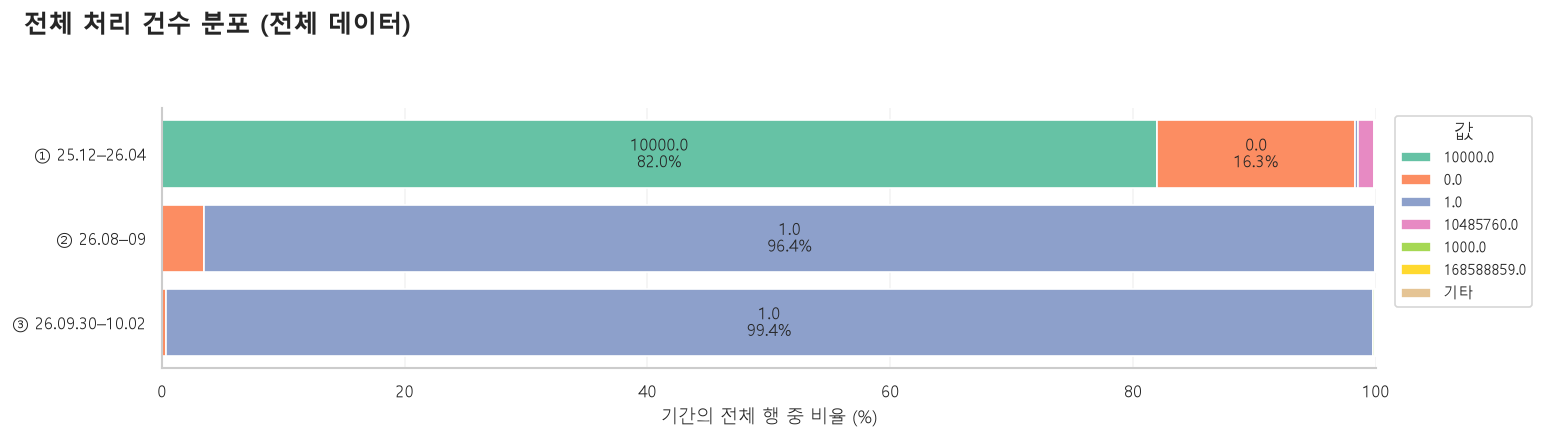

**실제 결과**

- ① 25.12–26.04: 최빈값 10000.0, 2,847,140건 (81.97%).
- ② 26.08–09: 최빈값 1.0, 205,920건 (96.45%).
- ③ 26.09.30–10.02: 최빈값 1.0, 27,247건 (99.42%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

In [8]:
plot_numeric_distributions(df, plot_df, ['totalCount'])


### 수치 분포: `successCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

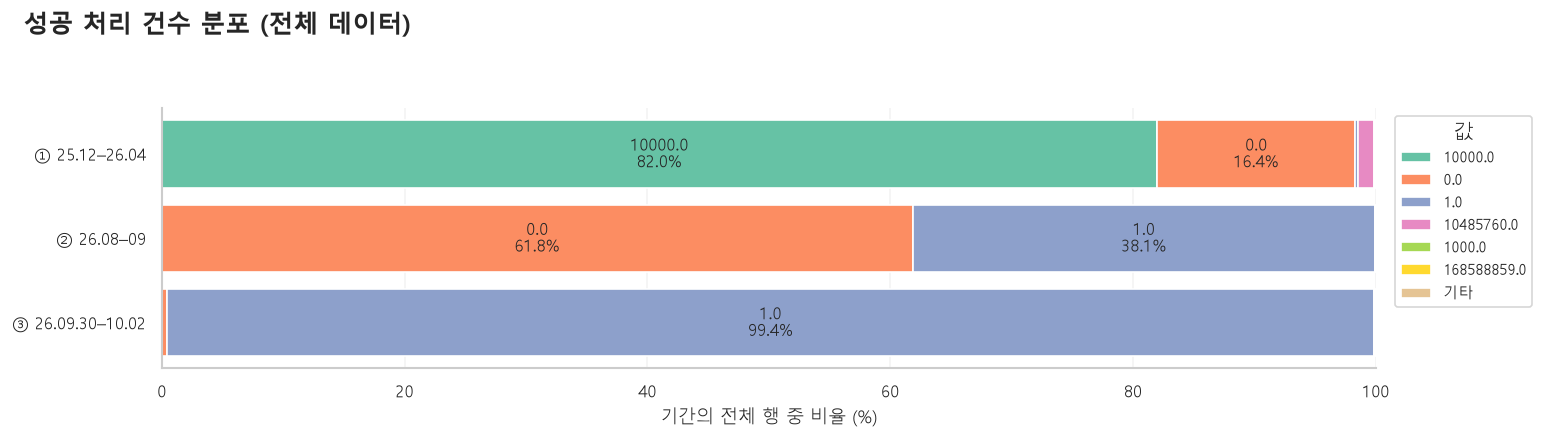

**실제 결과**

- ① 25.12–26.04: 최빈값 10000.0, 2,847,090건 (81.97%).
- ② 26.08–09: 최빈값 0.0, 132,046건 (61.85%).
- ③ 26.09.30–10.02: 최빈값 1.0, 27,246건 (99.42%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

In [9]:
plot_numeric_distributions(df, plot_df, ['successCount'])


### 수치 분포: `errorCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

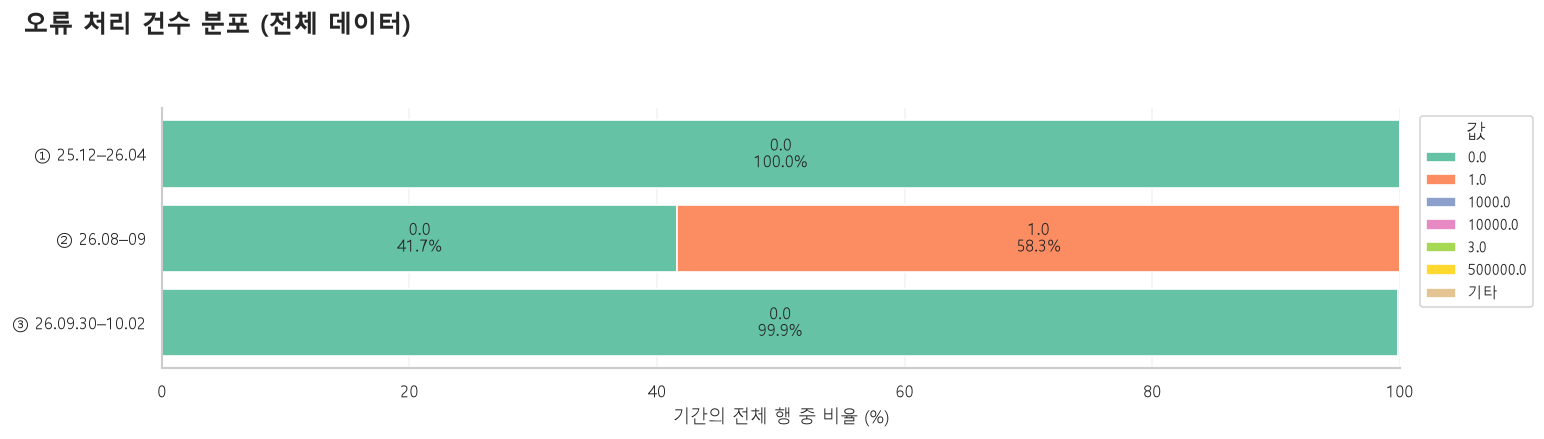

**실제 결과**

- ① 25.12–26.04: 최빈값 0.0, 3,473,096건 (99.99%).
- ② 26.08–09: 최빈값 1.0, 124,572건 (58.35%).
- ③ 26.09.30–10.02: 최빈값 0.0, 27,375건 (99.89%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

In [10]:
plot_numeric_distributions(df, plot_df, ['errorCount'])


### 수치 분포: `retryCount`

기간별 분포를 같은 축으로 비교하고 바로 아래 결과 해석을 읽습니다.

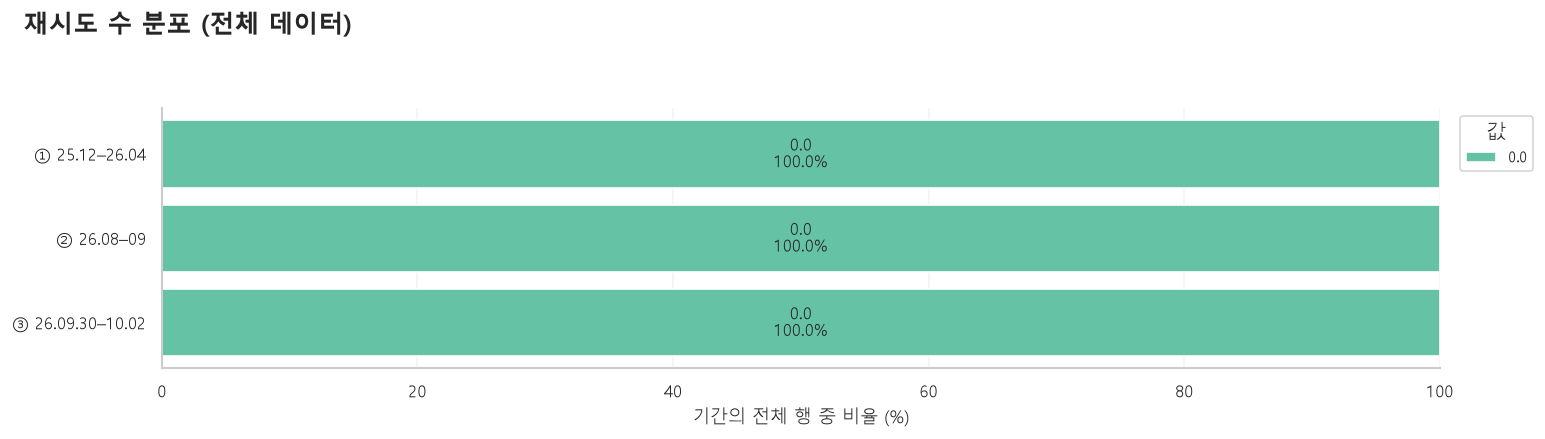

**실제 결과**

- ① 25.12–26.04: 최빈값 0.0, 3,473,285건 (100.00%).
- ② 26.08–09: 최빈값 0.0, 213,509건 (100.00%).
- ③ 26.09.30–10.02: 최빈값 0.0, 27,405건 (100.00%).

**의미**: 모든 유효 값이 같습니다. 이 표본에서는 이 변수만으로 로그를 구분할 수 없습니다.

**모델 개발에 반영**: 상수 피처는 현재 모델에서 변별력이 없습니다. 향후 새 값 출현은 별도로 감시합니다.

In [11]:
plot_numeric_distributions(df, plot_df, ['retryCount'])


### 3.1 가장 긴 실행은 별도 확인

긴 실행이 실제 지연인지, 배치 업무의 정상 실행인지 상태와 업무 종류를 확인합니다.
아래 표는 전체 데이터의 상위 실행이며, 표본 히스토그램에 없을 수도 있습니다.

In [ ]:
display(df.nlargest(10, "duration_ms")[["source_period", "transactionId", "startTime", "status", "duration_ms"]])
note(f"전체 유효 처리시간 최대 {df['duration_ms'].max():,.0f}ms; "
     f"음수 {df['negative_duration'].sum():,}건, 종료시각 결측 {df['missing_end'].sum():,}건.",
     "상위 실행만으로 정상/이상을 확정하지 않습니다. 완료 실행의 긴 꼬리와 종료 로그가 없는 실행은 다른 탐지 대상입니다.",
     "상위 실행을 업무별 분포와 비교하고, 미완료 로그는 별도의 경과시간 기반 감시를 설계합니다.")


## 4. 일별·시간별 트래픽과 처리시간 추이

기간별 그래프를 분리해 수집 공백을 가로질러 선을 잇지 않습니다.
집계는 전체 로그를 사용합니다. 실패율의 분모는 상태가 알려진 로그 수이며,
실패 상태 비율은 참고 지표입니다.

,observed_days,rows,median_daily_rows,max_daily_rows
source_period,,,,
25년12월24일-26년4월6일,60,3472973,29.5,659955
26년8월15일-26년9월14일,19,213496,9995.0,25926
26년9월30일-26년10월2일,3,27405,292.0,27047


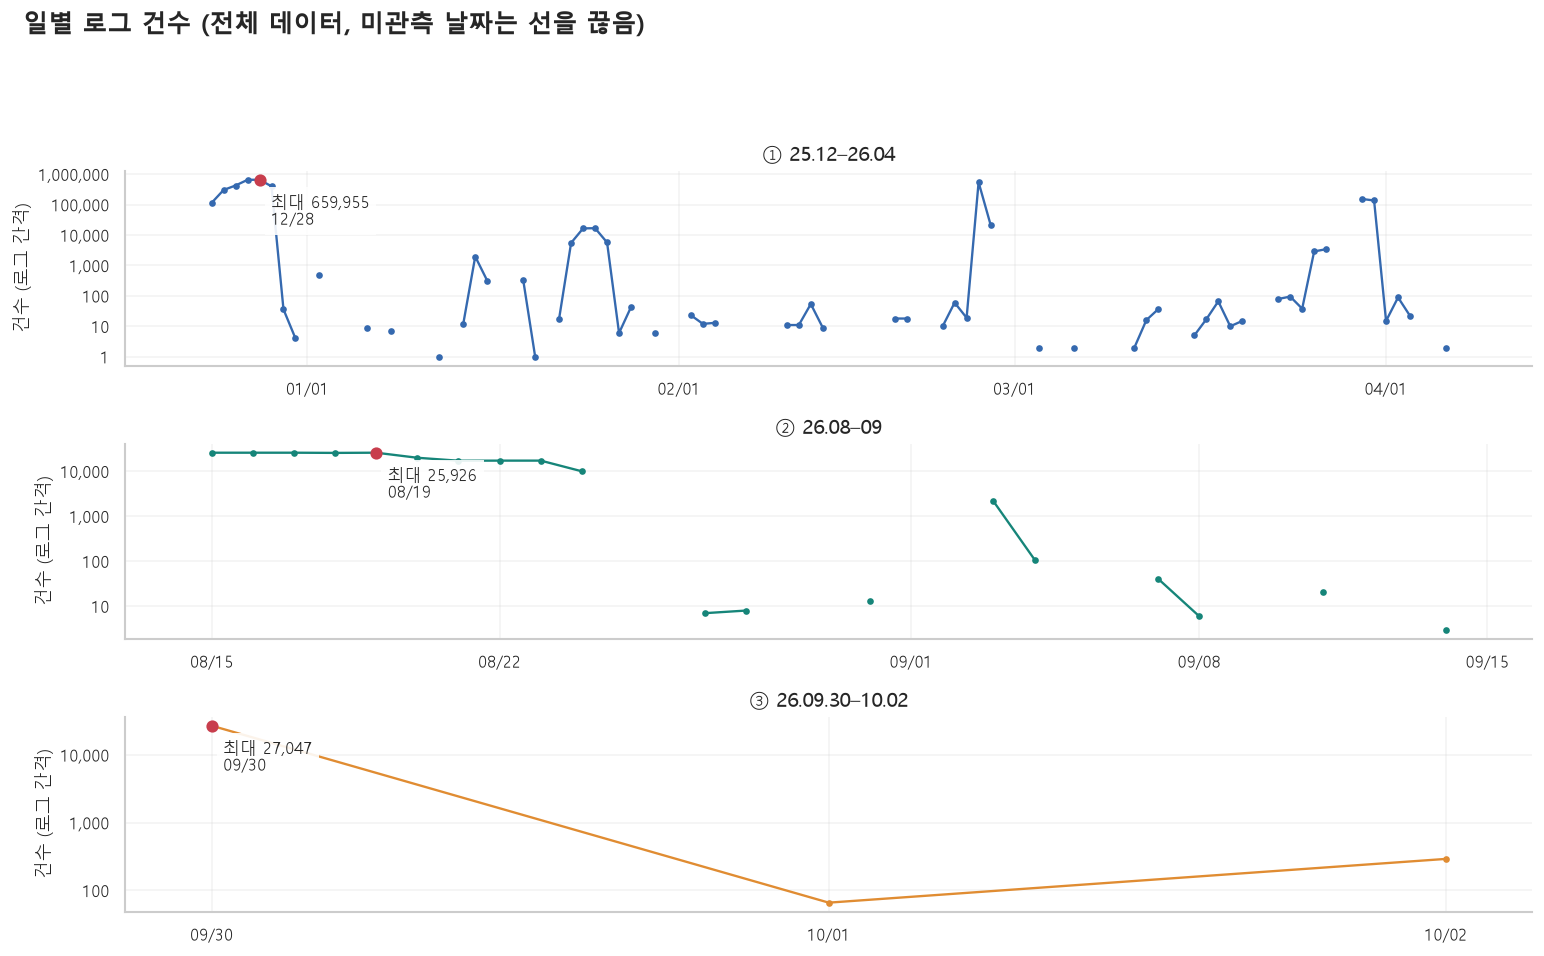

**실제 결과**

- ① 25.12–26.04: 관측 60일, 최대 659,955 (2025-12-28).
- ② 26.08–09: 관측 19일, 최대 25,926 (2026-08-19).
- ③ 26.09.30–10.02: 관측 3일, 최대 27,047 (2026-09-30).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

In [13]:
daily = time_summary(df, "D")
hourly = time_summary(df, "h")
display(daily.groupby("source_period", observed=True).agg(
    observed_days=("bin", "size"), rows=("rows", "sum"),
    median_daily_rows=("rows", "median"), max_daily_rows=("rows", "max")))
plot_period_timeseries(daily, "rows", "일별 로그 건수")


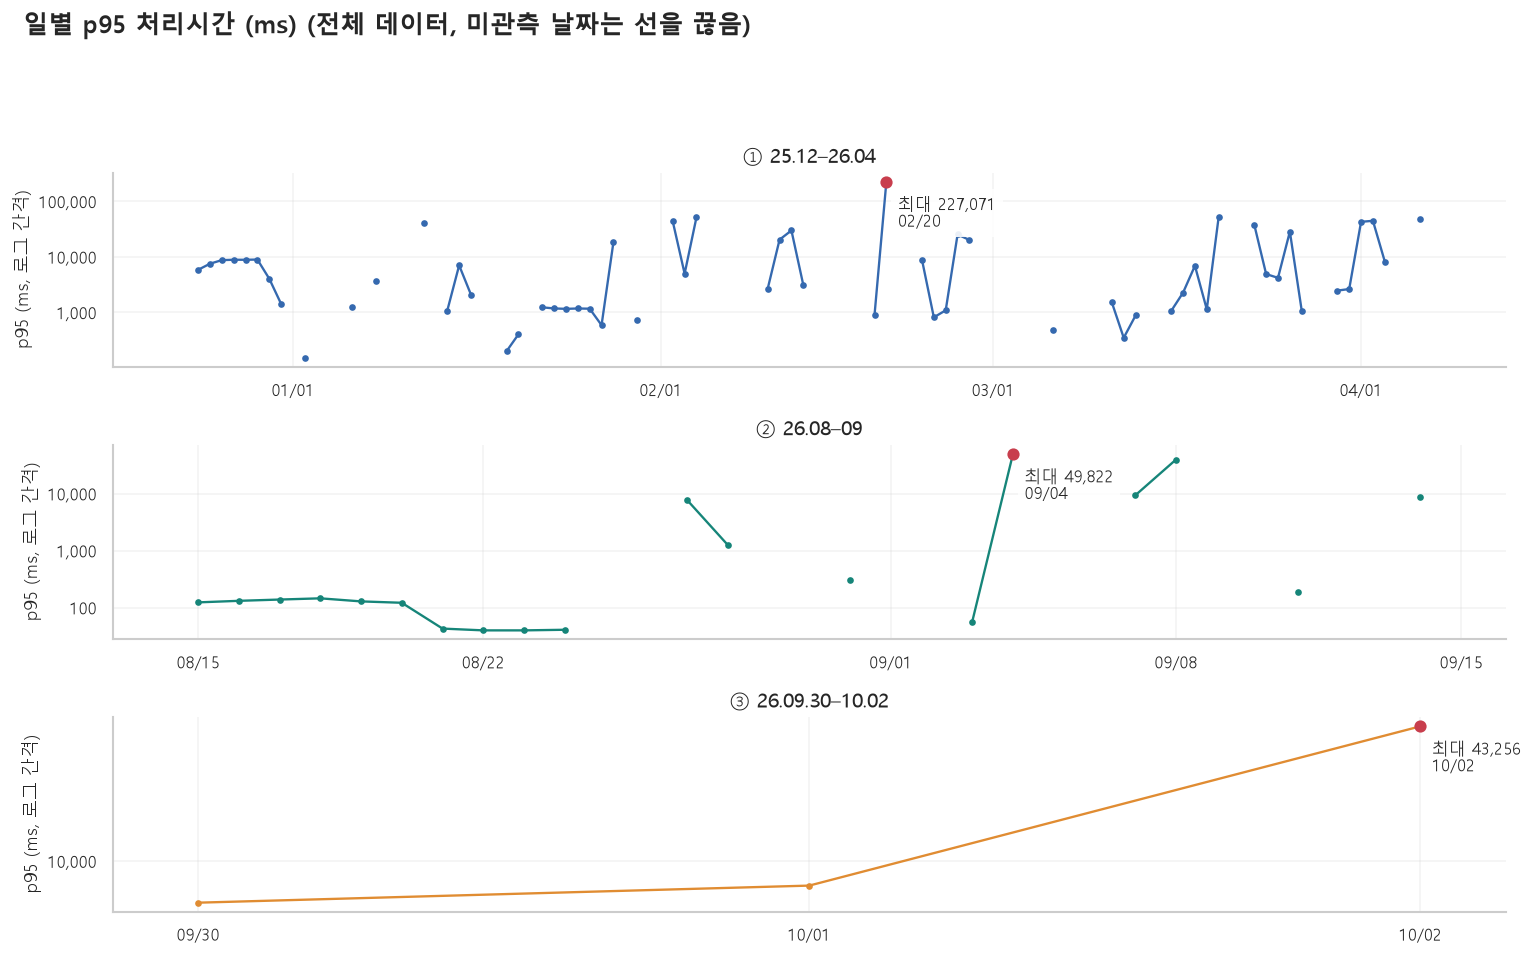

**실제 결과**

- ① 25.12–26.04: 관측 59일, 최대 227,071 (2026-02-20).
- ② 26.08–09: 관측 19일, 최대 49,822 (2026-09-04).
- ③ 26.09.30–10.02: 관측 3일, 최대 43,256 (2026-10-02).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

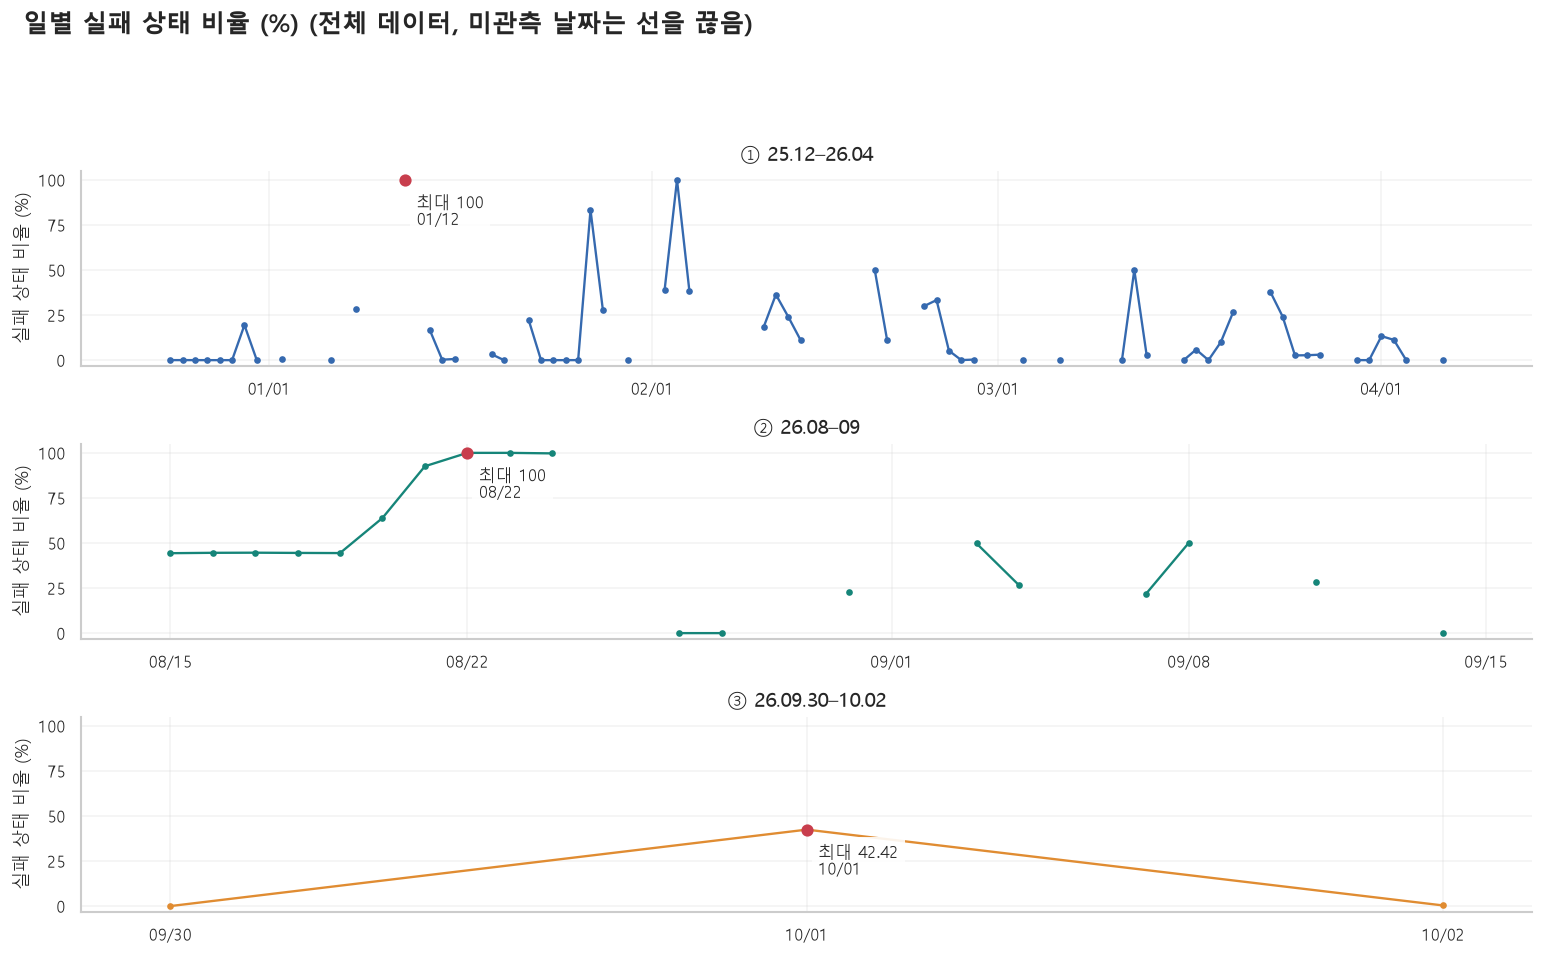

**실제 결과**

- ① 25.12–26.04: 관측 60일, 최대 100 (2026-01-12).
- ② 26.08–09: 관측 19일, 최대 100 (2026-08-22).
- ③ 26.09.30–10.02: 관측 3일, 최대 42.42 (2026-10-01).

**의미**: 건수·p95는 로그 눈금으로 작은 기간도 읽을 수 있게 했고, 실패율은 동일한 0–100% 범위로 표시했습니다. 수집되지 않은 날짜는 0이 아니라 미관측입니다. 날짜별 p95는 관측 건수가 적으면 불안정합니다.

**모델 개발에 반영**: 시간대·요일·업무량을 조건으로 한 기준선과 지연/실패 동시 변화를 검토합니다. 건수 증가만으로 장애를 판정하지 않습니다.

rows  observed_days  rows_per_observed_day
source_period     month                                                 
25년12월24일-26년4월6일 2025-12  2560700              8              320087.50
                  2026-01    47839             17                2814.06
                  2026-02   566944             14               40496.00
                  2026-03   297362             17               17491.88
                  2026-04      128              4                  32.00
26년8월15일-26년9월14일 2026-08   211146             13               16242.00
                  2026-09     2350              6                 391.67
26년9월30일-26년10월2일 2026-09    27047              1               27047.00
                  2026-10      358              2                 179.00

In [14]:
plot_period_timeseries(daily, "p95_ms", "일별 p95 처리시간 (ms)")
plot_period_timeseries(daily, "failure_pct", "일별 실패 상태 비율 (%)")
monthly = daily.assign(month=daily["bin"].dt.to_period("M").astype(str)).groupby(
    ["source_period", "month"], observed=True).agg(rows=("rows", "sum"), observed_days=("bin", "size"))
monthly["rows_per_observed_day"] = monthly["rows"] / monthly["observed_days"]
display(monthly.round(2))


### 4.1 요일·시간대 패턴

요일별 관측 날짜 수로 정규화한 시간대별 로그량을 봅니다. 아래 0은 관측된 날짜의
해당 시간대에서 발견된 행이 없다는 뜻이며, 수집이 완전했다는 보장은 아닙니다.
야간·주말이라는 이유만으로 이상으로 판정하지 않습니다.

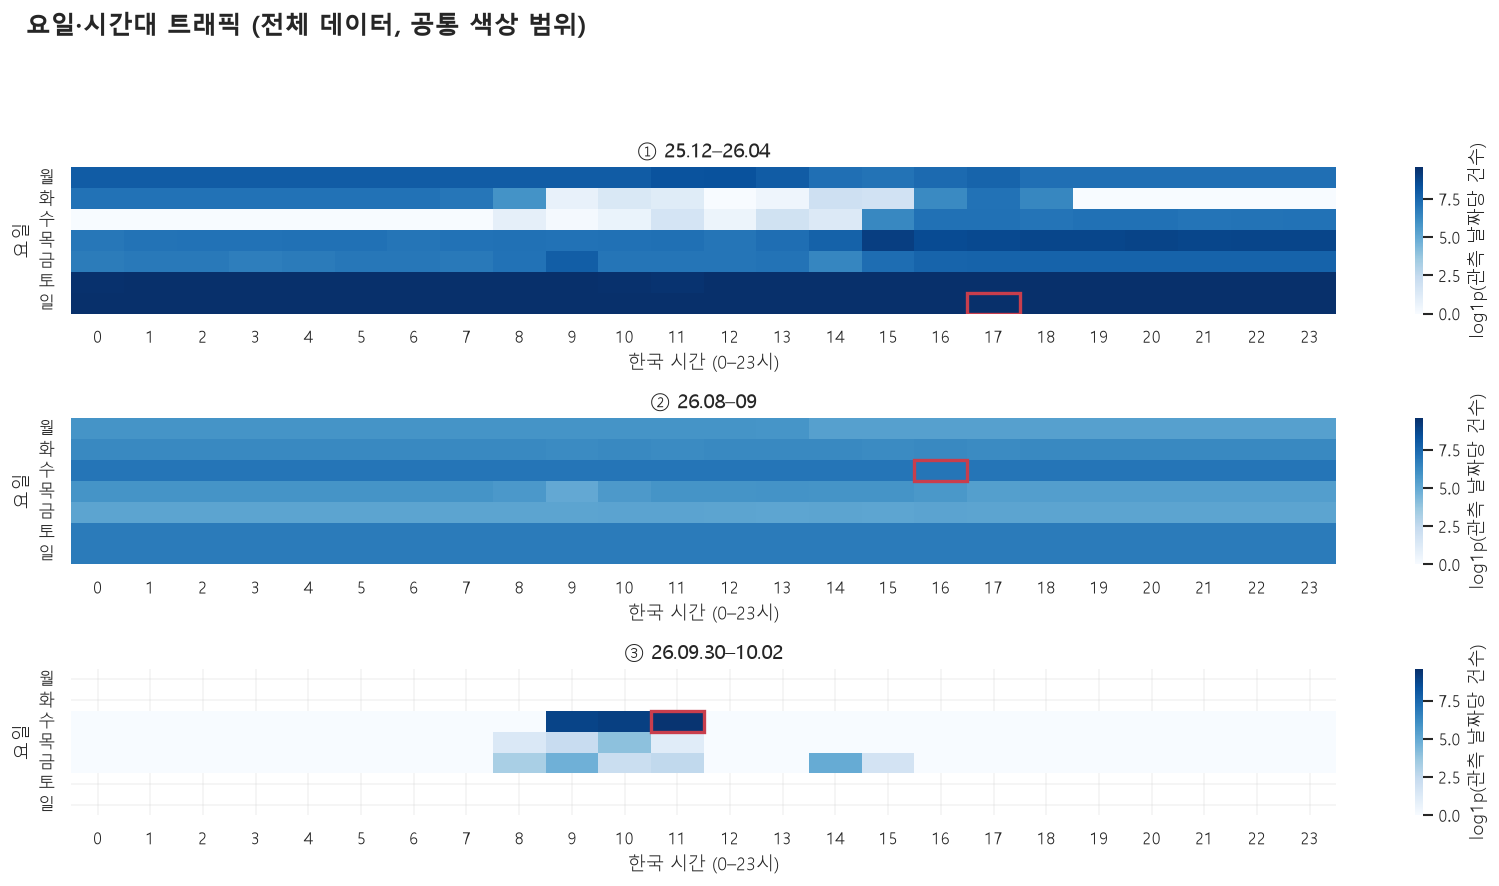

**실제 결과**

- ① 25.12–26.04: 최다 시간대 일요일 17시, 관측 날짜당 14,200.0건. 빨간 테두리로 표시했습니다.
- ② 26.08–09: 최다 시간대 수요일 16시, 관측 날짜당 1,086.0건. 빨간 테두리로 표시했습니다.
- ③ 26.09.30–10.02: 최다 시간대 수요일 11시, 관측 날짜당 12,111.0건. 빨간 테두리로 표시했습니다.

**의미**: 흰색은 해당 요일의 관측 날짜가 없다는 뜻입니다. 파란색 농도는 모든 기간에 같은 로그 색상 범위를 사용합니다. 0건인 칸도 수집이 완전했다는 증거는 아닙니다.

**모델 개발에 반영**: 야간/주말을 무조건 이상으로 취급하지 않고 관측된 주기 패턴을 시간 피처 또는 계절성 기준선에 반영합니다.

In [15]:
plot_hour_pattern(df)


### 4.2 과거 24시간 기준 트래픽 급증·급감 후보

현재 시각을 제외한 과거 24시간의 중앙값/MAD를 기준으로 합니다.
기간별 기준선을 다시 시작하고 빈 시간 구간은 결측으로 둡니다.
이력 6개 미만 또는 MAD=0이면 점수를 산출하지 않습니다.
이는 점검용 규칙이며 계절성 모델이나 확정된 이상 라벨이 아닙니다.

,bins,observed_bins,comparable_bins,candidate_bins
source_period,,,,
25년12월24일-26년4월6일,2471,396,249,53
26년8월15일-26년9월14일,735,258,14,4
26년9월30일-26년10월2일,55,13,0,0


,bin,rows,known_status,failures,median_ms,p95_ms,failure_pct,volume_robust_z,reference_available,candidate,source_period,absolute_z
2333,2026-03-31 15:00:00,15.0,15.0,0.0,72.0,7295.20,0.000000,-1957.610131,True,True,25년12월24일-26년4월6일,1957.610131
2328,2026-03-31 10:00:00,15.0,15.0,1.0,65.0,128.00,6.666667,-1648.047163,True,True,25년12월24일-26년4월6일,1648.047163
2944,2026-09-03 17:00:00,4.0,4.0,4.0,50627.0,52116.45,100.000000,-1040.576206,True,True,26년8월15일-26년9월14일,1040.576206
795,2026-01-26 13:00:00,1.0,1.0,1.0,305.0,305.00,100.000000,-474.532629,True,True,25년12월24일-26년4월6일,474.532629
2334,2026-03-31 16:00:00,5594.0,5594.0,3.0,1017.0,2595.35,0.053629,-260.222340,True,True,25년12월24일-26년4월6일,260.222340
141,2025-12-30 07:00:00,18.0,18.0,3.0,313.0,9571.65,16.666667,-220.011317,True,True,25년12월24일-26년4월6일,220.011317
2336,2026-03-31 18:00:00,6497.0,6497.0,0.0,440.0,2681.25,0.000000,-216.861696,True,True,25년12월24일-26년4월6일,216.861696
123,2025-12-29 13:00:00,14266.0,14266.0,2.0,2750.5,9135.50,0.014019,-213.882983,True,True,25년12월24일-26년4월6일,213.882983
2326,2026-03-31 08:00:00,4044.0,4044.0,1.0,1493.5,4950.85,0.024728,-150.414194,True,True,25년12월24일-26년4월6일,150.414194
127,2025-12-29 17:00:00,15541.0,15541.0,1.0,1615.0,9170.00,0.006435,-149.183139,True,True,25년12월24일-26년4월6일,149.183139


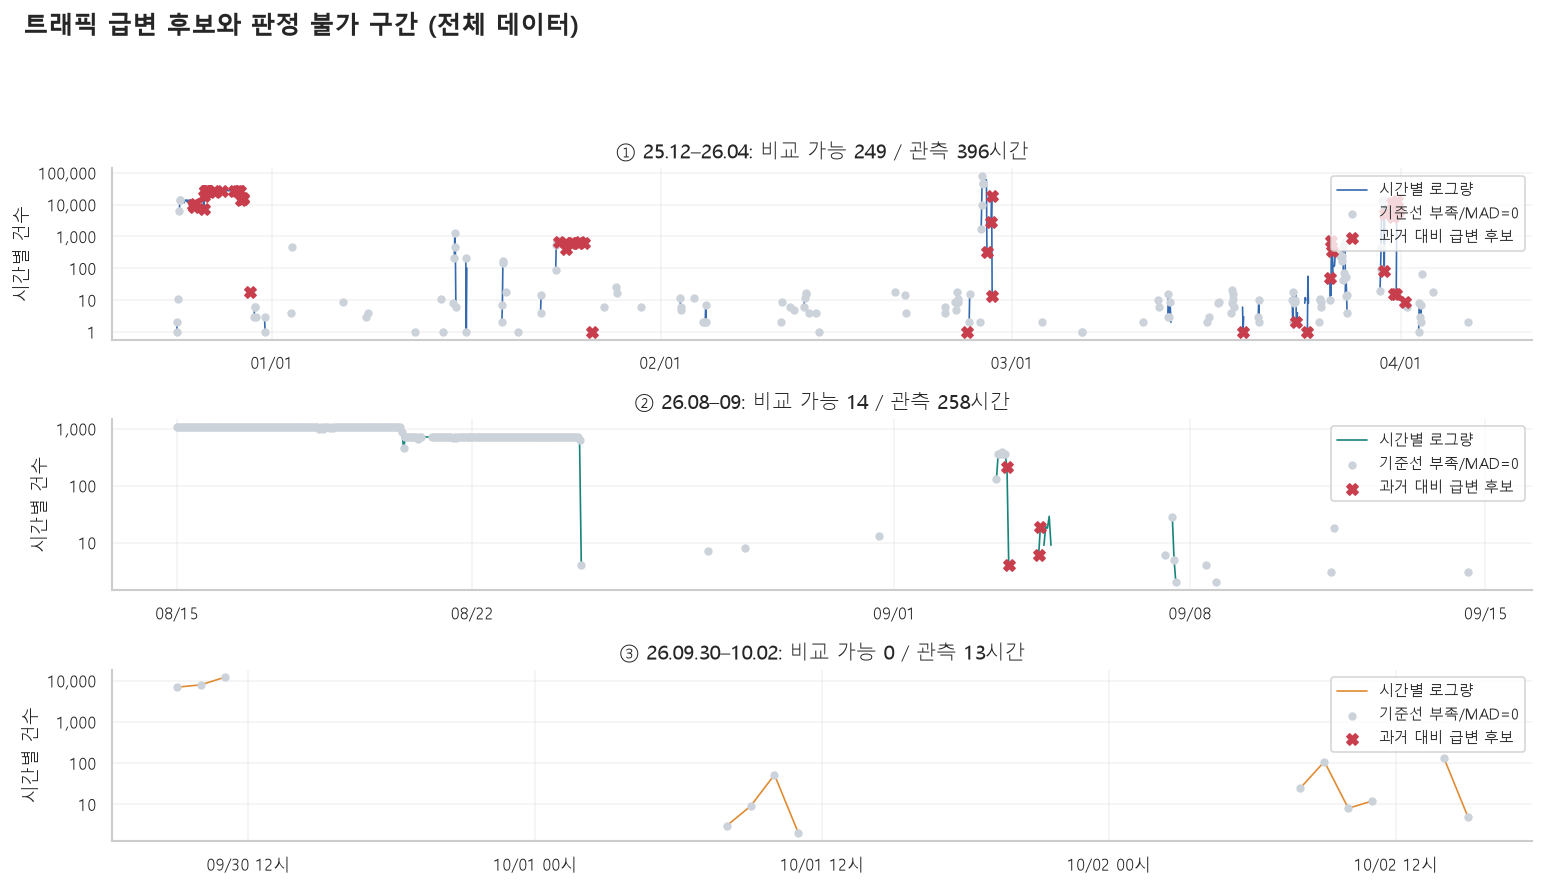

**실제 결과**

- ① 25.12–26.04: 기준선 계산 가능 249시간, 후보 53시간, 기준선 없는 관측 147시간.
- ② 26.08–09: 기준선 계산 가능 14시간, 후보 4시간, 기준선 없는 관측 244시간.
- ③ 26.09.30–10.02: 기준선 계산 가능 0시간, 후보 0시간, 기준선 없는 관측 13시간.

**의미**: 빨간 X는 과거 24시간 로그량 중앙값/MAD 대비 급변 후보입니다. 회색 점은 정상 판정이 아니라 이력 부족 또는 MAD=0으로 비교할 수 없는 관측입니다.

**모델 개발에 반영**: 후보 수와 함께 평가 가능한 구간의 비율을 보고합니다. 짧은 최신 기간에서 후보 0개가 나와도 정상이라고 결론 내리지 않습니다.

In [16]:
traffic_candidates = hourly_history_candidates(hourly)
display(traffic_candidates.groupby("source_period", observed=True).agg(
    bins=("bin", "size"), observed_bins=("rows", "count"),
    comparable_bins=("reference_available", "sum"), candidate_bins=("candidate", "sum")))
display(traffic_candidates.loc[traffic_candidates["candidate"]].assign(
    absolute_z=lambda x: x["volume_robust_z"].abs()).nlargest(15, "absolute_z"))
plot_traffic_candidates(traffic_candidates)


## 5. 어댑터·채널·허브 흐름과 처리 성능

업무 흐름별 로그량, p95/p99 처리시간과 상태 분포를 함께 비교합니다.
그래프는 각 기간의 구성 비율을 비교하며 표의 집계·분위수는 전체 데이터입니다.

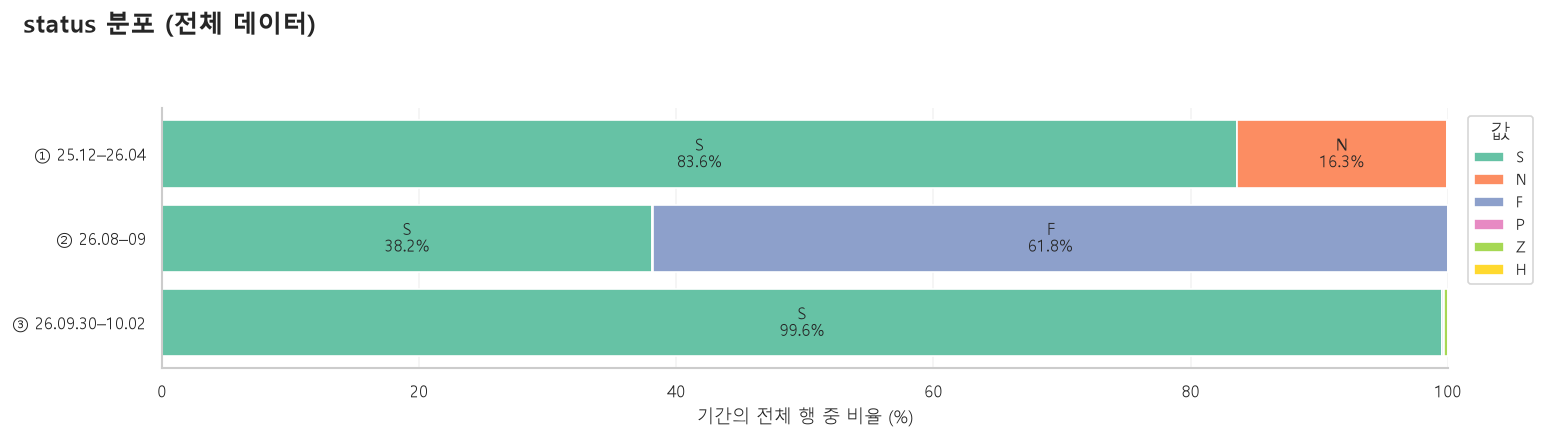

**실제 결과**

- ① 25.12–26.04: 최빈값 S, 2,904,451건 (83.62%).
- ② 26.08–09: 최빈값 F, 131,894건 (61.77%).
- ③ 26.09.30–10.02: 최빈값 S, 27,287건 (99.57%).

**의미**: 기간별 막대의 길이를 100%로 맞췄기 때문에 규모가 아니라 값의 구성 차이를 비교합니다. 처리 건수의 의미·단위는 어댑터마다 다를 수 있습니다.

**모델 개발에 반영**: 연속형 정규분포를 가정하지 않고 범주형/카운트 특성을 반영합니다. 기간·업무 구성이 다른데 공통 IQR을 적용하면 정상 값도 대량 경보가 될 수 있습니다.

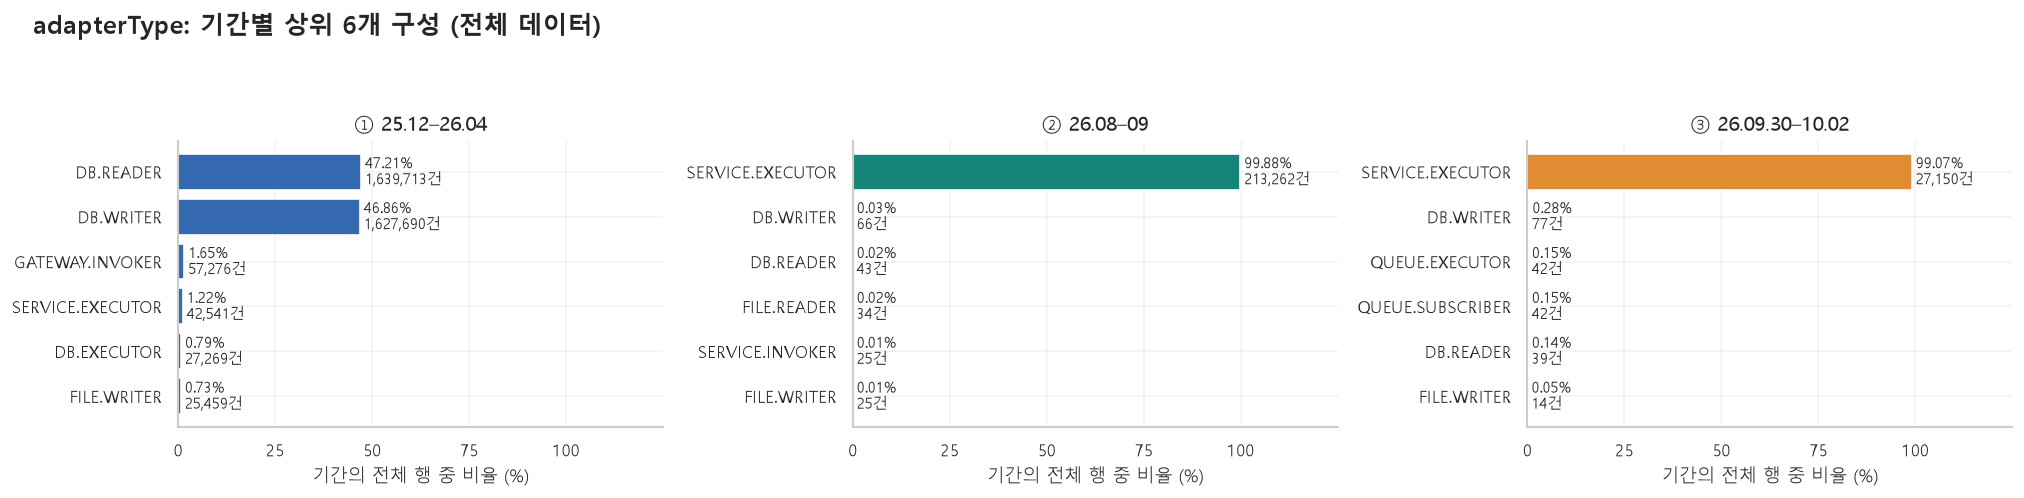

**실제 결과**

- ① 25.12–26.04: 최빈 DB.READER가 47.21%, 상위 6개 합계 98.46%.
- ② 26.08–09: 최빈 SERVICE.EXECUTOR가 99.88%, 상위 6개 합계 99.97%.
- ③ 26.09.30–10.02: 최빈 SERVICE.EXECUTOR가 99.07%, 상위 6개 합계 99.85%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

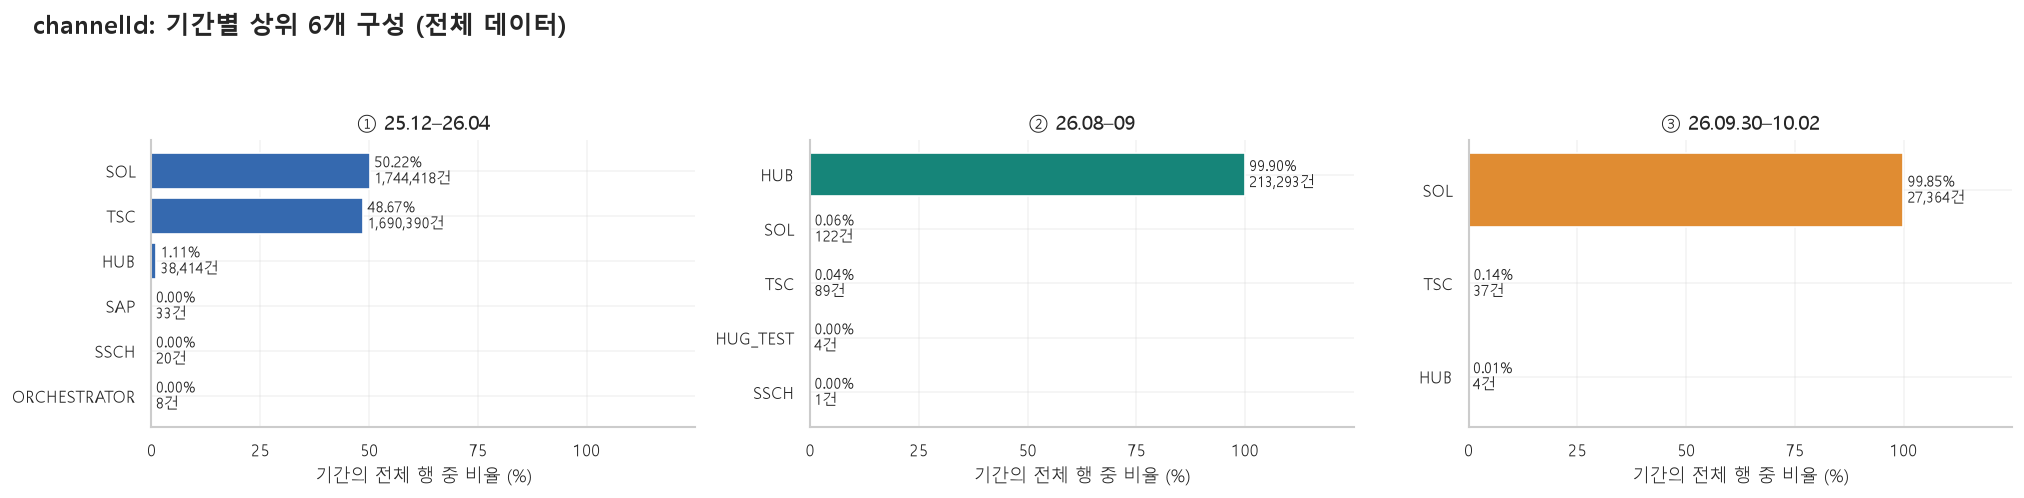

**실제 결과**

- ① 25.12–26.04: 최빈 SOL가 50.22%, 상위 6개 합계 100.00%.
- ② 26.08–09: 최빈 HUB가 99.90%, 상위 5개 합계 100.00%.
- ③ 26.09.30–10.02: 최빈 SOL가 99.85%, 상위 3개 합계 100.00%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

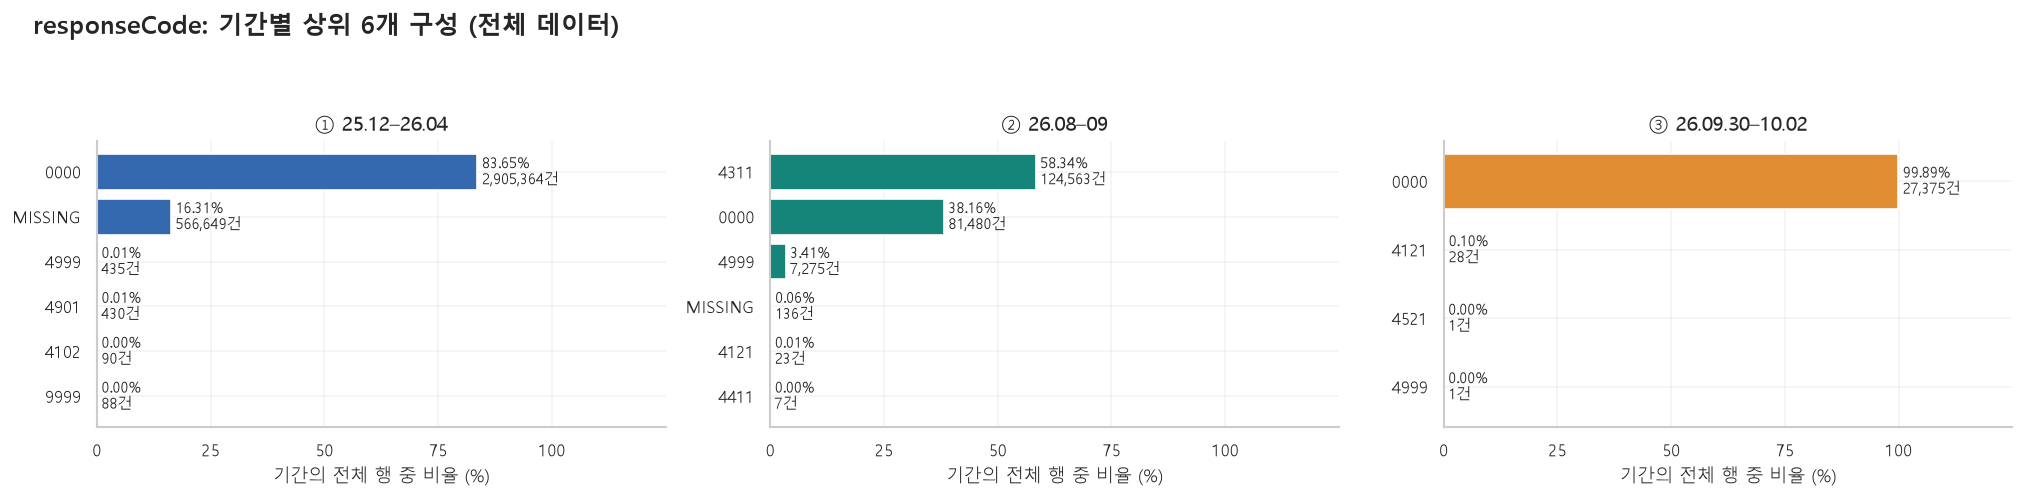

**실제 결과**

- ① 25.12–26.04: 최빈 0000가 83.65%, 상위 6개 합계 99.99%.
- ② 26.08–09: 최빈 4311가 58.34%, 상위 6개 합계 99.99%.
- ③ 26.09.30–10.02: 최빈 0000가 99.89%, 상위 4개 합계 100.00%.

**의미**: 전체 기간을 합산한 순위 대신 각 기간의 상위 범주를 따로 보여줍니다. 업무 구성이나 어댑터 역할이 바뀌면 처리시간과 실패율의 정상 기준도 바뀔 수 있습니다.

**모델 개발에 반영**: 범주별 정상 기준선과 신규 범주 감시를 검토합니다. 상태와 응답코드는 사후 해석용이며 실패 상태 자체를 비지도 모델의 정답으로 사용하지 않습니다.

status,F,H,N,P,S,Z
source_period,,,,,,
25년12월24일-26년4월6일,0.02,0.00,16.28,0.06,83.62,0.01
26년8월15일-26년9월14일,61.77,0.00,0.06,0.00,38.15,0.01
26년9월30일-26년10월2일,0.11,0.01,0.00,0.00,99.57,0.31


rows  median_ms     p95_ms  \
source_period     flow_key                                                      
25년12월24일-26년4월6일 HUB → DB.READER → TSC         1638494      424.0     647.00   
                  HUB → DB.WRITER → SOL         1614557     5878.0    9210.00   
26년8월15일-26년9월14일 HUB → SERVICE.EXECUTOR → HUB   213241       31.0     129.00   
25년12월24일-26년4월6일 HUB → GATEWAY.INVOKER → SOL     57247      233.5    1776.90   
26년9월30일-26년10월2일 HUB → SERVICE.EXECUTOR → SOL    27150     5969.0    6364.85   
25년12월24일-26년4월6일 DIRECT → FILE.READER → TSC      24466      454.0    1076.25   
                  DIRECT → FILE.WRITER → SOL      24380      906.0    1269.00   
                  HUB → SERVICE.EXECUTOR → SOL    22810      103.0    7078.70   
                  HUB → DB.EXECUTOR → SOL         22783       95.5     174.50   
                  HUB → SERVICE.EXECUTOR → HUB    19675     7038.0    7055.00   
                  HUB → DB.WRITER → TSC           13117      222.5    1598.90   
                  HUB → QUEUE.SUBSCRIBER → HUB    13048    41437.5  138933.95   
                  HUB → QUEUE.EXECUTOR → TSC      13041      362.5   64009.50   
                  HUB → DB.EXECUTOR → HUB          4467       46.0      64.00   
                  HUB → DB.READER → SOL            1219      185.0    1863.20   
                  HUB → QUEUE.PUBLISHER → HUB      1145      889.0    1501.90   
                  HUB → FILE.WRITER → SOL           743       97.0   19621.80   
                  HUB → FILE.READER → TSC           625      219.0   55346.00   
                  DIRECT → FILE.WRITER → TSC        277       42.0   47057.20   
                  DIRECT → FILE.READER → SOL        276       19.0   47140.75   
                  HUB → DB.DELETER → SOL            177    35471.0  554767.80   
                  HUB → DATA.TRANSFORMER → TSC      173      137.0     689.00   
26년9월30일-26년10월2일 HUB → DB.WRITER → SOL              77       56.0    7598.80   
25년12월24일-26년4월6일 HUB → DB.UPDATER → SOL             73      107.0     623.75   
                  HUB → FILE.READER → SOL            65     2600.0   24620.00   

                                                   p99_ms  
source_period     flow_key                                 
25년12월24일-26년4월6일 HUB → DB.READER → TSC           1094.00  
                  HUB → DB.WRITER → SOL          10277.00  
26년8월15일-26년9월14일 HUB → SERVICE.EXECUTOR → HUB     170.00  
25년12월24일-26년4월6일 HUB → GATEWAY.INVOKER → SOL     1932.68  
26년9월30일-26년10월2일 HUB → SERVICE.EXECUTOR → SOL   44926.71  
25년12월24일-26년4월6일 DIRECT → FILE.READER → TSC     24157.38  
                  DIRECT → FILE.WRITER → SOL      1529.00  
                  HUB → SERVICE.EXECUTOR → SOL   10127.26  
                  HUB → DB.EXECUTOR → SOL          181.30  
                  HUB → SERVICE.EXECUTOR → HUB    7991.66  
                  HUB → DB.WRITER → TSC          56947.27  
                  HUB → QUEUE.SUBSCRIBER → HUB  138948.39  
                  HUB → QUEUE.EXECUTOR → TSC     77873.10  
                  HUB → DB.EXECUTOR → HUB           96.00  
                  HUB → DB.READER → SOL          49651.24  
                  HUB → QUEUE.PUBLISHER → HUB     1537.18  
                  HUB → FILE.WRITER → SOL        67981.44  
                  HUB → FILE.READER → TSC       232233.76  
                  DIRECT → FILE.WRITER → TSC     50383.72  
                  DIRECT → FILE.READER → SOL     50442.25  
                  HUB → DB.DELETER → SOL        577770.36  
                  HUB → DATA.TRANSFORMER → TSC   29152.33  
26년9월30일-26년10월2일 HUB → DB.WRITER → SOL           7735.04  
25년12월24일-26년4월6일 HUB → DB.UPDATER → SOL         36919.19  
                  HUB → FILE.READER → SOL        30334.80

**실제 결과**

- 흐름 표는 기간·허브·어댑터·채널별 전체 통계입니다. 처리 건수가 다른 어댑터를 단순 평균 시간으로 비교하지 않습니다.

**의미**: DB 읽기/쓰기와 서비스 실행은 역할·처리 단위가 달라 전체 통합 시간 분포가 서로 다른 정상 업무를 섞을 수 있습니다.

**모델 개발에 반영**: 어댑터/업무별 지연 기준선과 처리 건수 피처의 단위를 확인합니다.

In [17]:
df["flow_key"] = (text(df["processHubId"]) + " → " + text(df["adapterType"]) + " → " + text(df["channelId"])).astype("category")
plot_categories(df, ["status", "adapterType", "channelId", "responseCode"])
display(pd.crosstab(df["source_period"], text(df["status"]), normalize="index").mul(100).round(2))
flow_summary = df.groupby(["source_period", "flow_key"], observed=True).agg(
    rows=("processId", "size"), median_ms=("duration_ms", "median"),
    p95_ms=("duration_ms", lambda s: s.quantile(.95)), p99_ms=("duration_ms", lambda s: s.quantile(.99)))
display(flow_summary.sort_values("rows", ascending=False).head(25))
note("흐름 표는 기간·허브·어댑터·채널별 전체 통계입니다. 처리 건수가 다른 어댑터를 단순 평균 시간으로 비교하지 않습니다.",
     "DB 읽기/쓰기와 서비스 실행은 역할·처리 단위가 달라 전체 통합 시간 분포가 서로 다른 정상 업무를 섞을 수 있습니다.",
     "어댑터/업무별 지연 기준선과 처리 건수 피처의 단위를 확인합니다.")


valid_rows  median_ms    p95_ms
source_period     adapterType                                      
25년12월24일-26년4월6일 DB.READER            1425358      424.0    647.00
                  DB.WRITER            1425137     5878.0   9210.00
26년8월15일-26년9월14일 SERVICE.EXECUTOR      213139       31.0    129.00
26년9월30일-26년10월2일 SERVICE.EXECUTOR       27150     5969.0   6364.85
25년12월24일-26년4월6일 FILE.READER            24895      452.0   1171.00
                  FILE.WRITER            22749      904.0   1282.00
                  DB.EXECUTOR             4480       46.0     65.00
                  SERVICE.EXECUTOR        2788     7038.0   7056.00
                  DB.UPDATER                97      111.0    601.40
26년9월30일-26년10월2일 DB.WRITER                 77       56.0   7598.80
25년12월24일-26년4월6일 DATA.TRANSFORMER          63      108.0   8592.30
                  GATEWAY.INVOKER           59      272.0   6019.20
26년8월15일-26년9월14일 DB.WRITER                 57      349.0   9593.80
25년12월24일-26년4월6일 DATA.MAPPER               50       99.5  43763.45
26년8월15일-26년9월14일 DB.READER                 43      170.0   9065.40
26년9월30일-26년10월2일 QUEUE.EXECUTOR            42       43.0     64.85
                  QUEUE.SUBSCRIBER          42     1053.5   1072.00
25년12월24일-26년4월6일 SERVICE.INVOKER           39    11360.0  54302.20
26년9월30일-26년10월2일 DB.READER                 39       75.0    589.30
26년8월15일-26년9월14일 FILE.READER               34      568.5  75025.40

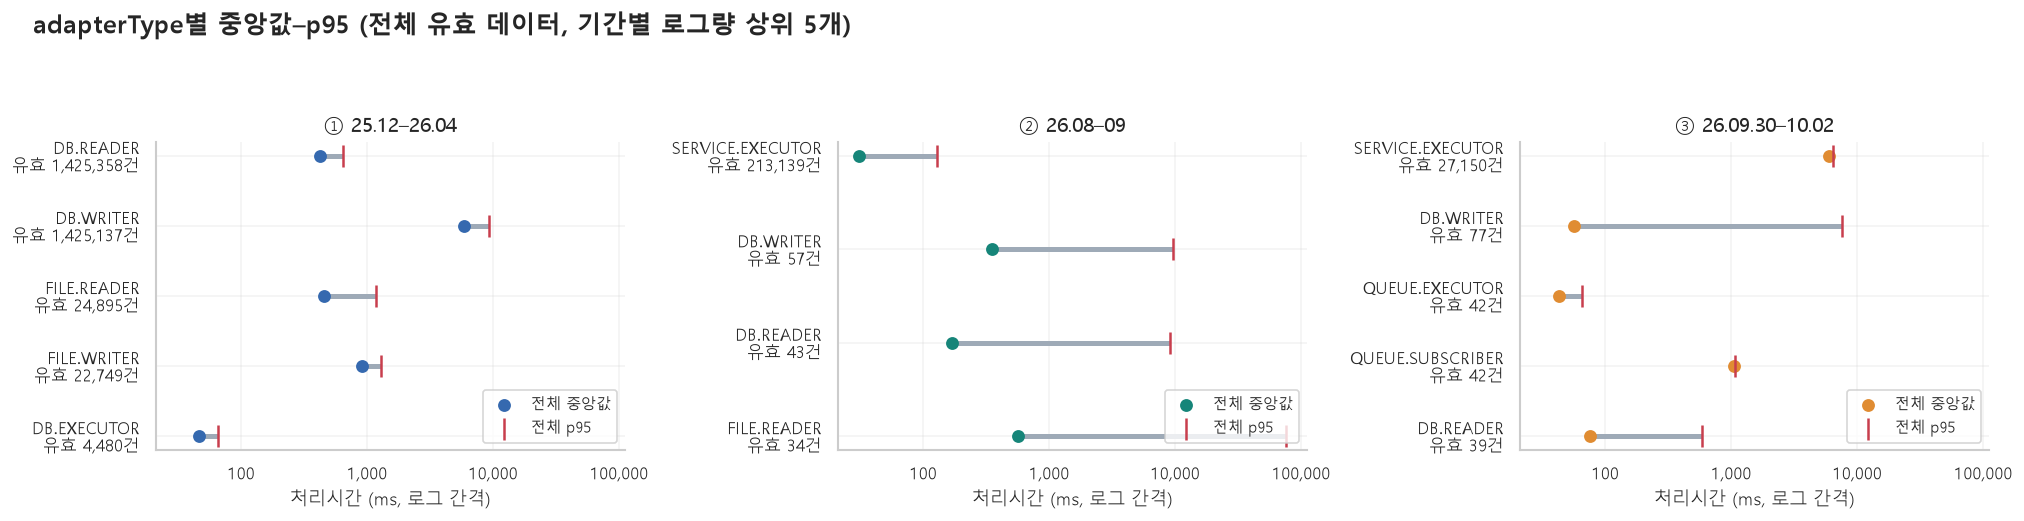

**실제 결과**

- ① 25.12–26.04: 최다 adapterType DB.READER, 중앙값 424ms, p95 647ms.
- ② 26.08–09: 최다 adapterType SERVICE.EXECUTOR, 중앙값 31ms, p95 129ms.
- ③ 26.09.30–10.02: 최다 adapterType SERVICE.EXECUTOR, 중앙값 5,969ms, p95 6,365ms.

**의미**: 점은 해당 어댑터의 중앙값, 빨간 세로선은 p95이며 선 길이는 긴 꼬리의 정도를 보여줍니다. 같은 x축에서 비교하므로 기간별 처리 방식의 차이가 드러납니다.

**모델 개발에 반영**: 전체 모델 외에 어댑터별 지연 기준선을 검토합니다. 로그가 많고 꼬리가 긴 그룹을 먼저 살피되 처리 건수와 정상 업무 정의를 함께 확인합니다.

**실제 결과**

- 어댑터별 유효 처리시간 30건 이상인 그룹의 중앙값·p95를 전체 데이터로 비교합니다.

**의미**: 상위 어댑터 표의 p95는 해당 그룹의 긴 꼬리이며 전체 기간 p95와 같지 않습니다. 빠른 업무가 많다고 다른 업무도 동일 시간 안에 끝나야 하는 것은 아닙니다.

**모델 개발에 반영**: 주요 어댑터의 업무별 시간 분포와 처리 단위를 분리해 기준선을 검토합니다.

In [18]:
adapter_quantiles = df.groupby(["source_period", "adapterType"], observed=True)["duration_ms"].agg(
    valid_rows="count", median_ms="median", p95_ms=lambda s: s.quantile(.95))
display(adapter_quantiles.loc[adapter_quantiles.valid_rows.ge(30)].sort_values("valid_rows", ascending=False).head(20))
from log_analysis_visuals import plot_group_quantiles
plot_group_quantiles(adapter_quantiles, "adapterType")
note("어댑터별 유효 처리시간 30건 이상인 그룹의 중앙값·p95를 전체 데이터로 비교합니다.",
     "상위 어댑터 표의 p95는 해당 그룹의 긴 꼬리이며 전체 기간 p95와 같지 않습니다. 빠른 업무가 많다고 다른 업무도 동일 시간 안에 끝나야 하는 것은 아닙니다.",
     "주요 어댑터의 업무별 시간 분포와 처리 단위를 분리해 기준선을 검토합니다.")


## 6. 전체 IQR와 업무 그룹별 처리시간 기준선

전체 IQR은 여러 업무·기간의 분포를 섞으므로 참고용입니다.
`source_period + processId`별 로그 처리시간의 중앙값/MAD 기준을 함께 봅니다.
유효 처리시간 30건 이상, MAD>0인 그룹에서만 상대적인 지연 후보를 계산합니다.
MAD=0/표본 부족은 판정 불가로 남깁니다. 이 전체 기간 EDA 기준선은
뒤의 시간 분리 모델 입력에 사용하지 않아 미래 정보 누출을 방지합니다.

In [19]:
iqr_table, iqr_flags = iqr_summary(df, ['duration_ms', 'totalCount', 'retryCount'])
df["iqr_candidate"] = iqr_flags.any(axis=1)
display(iqr_table.round(3))
context_profile, context_result = contextual_duration(df, "processId")
df[context_result.columns] = context_result
display(df.groupby("source_period", observed=True).agg(
    rows=("transactionId", "size"), iqr_candidates=("iqr_candidate", "sum"),
    context_comparable=("context_comparable", "sum"), context_candidates=("context_candidate", "sum")))
display(context_profile.sort_values("support", ascending=False).head(15))


,feature,q1,q3,IQR,candidate_count,candidate_pct
0,duration_ms,391.0,5572.0,5181.0,7284,0.196
1,totalCount,10000.0,10000.0,0.0,867052,23.344
2,retryCount,0.0,0.0,0.0,0,0.000


,rows,iqr_candidates,context_comparable,context_candidates
source_period,,,,
25년12월24일-26년4월6일,3473285,631711,2903874,9821
26년8월15일-26년9월14일,213509,213507,213072,18545
26년9월30일-26년10월2일,27405,27405,27276,12541


support    median       MAD
source_period     processId                                                
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001_PR001      84298  3.663562  0.167054
                  IF_REST_ERROR_RESPONSE_PR001    82527  2.890372  0.117783
25년12월24일-26년4월6일 IF_DB2DB_908_PR001              47443  5.934894  0.227784
                  IF_DB2DB_908_PR002              47436  8.500657  0.449954
                  IF_DB2DB_916_PR001              47316  5.961005  0.257223
                  IF_DB2DB_906_PR001              47313  5.976351  0.242249
                  IF_DB2DB_905_PR001              47309  6.037871  0.262915
                  IF_DB2DB_916_PR002              47308  8.507547  0.446869
                  IF_DB2DB_919_PR001              47307  6.013715  0.251664
                  IF_DB2DB_905_PR002              47306  8.514991  0.447145
                  IF_DB2DB_906_PR002              47305  8.497603  0.451694
                  IF_DB2DB_919_PR002              47302  8.501775  0.457537
                  IF_DB2DB_917_PR001              47294  5.986452  0.286425
                  IF_DB2DB_917_PR002              47288  8.503500  0.451203
                  IF_DB2DB_902_PR001              47286  5.926926  0.246860

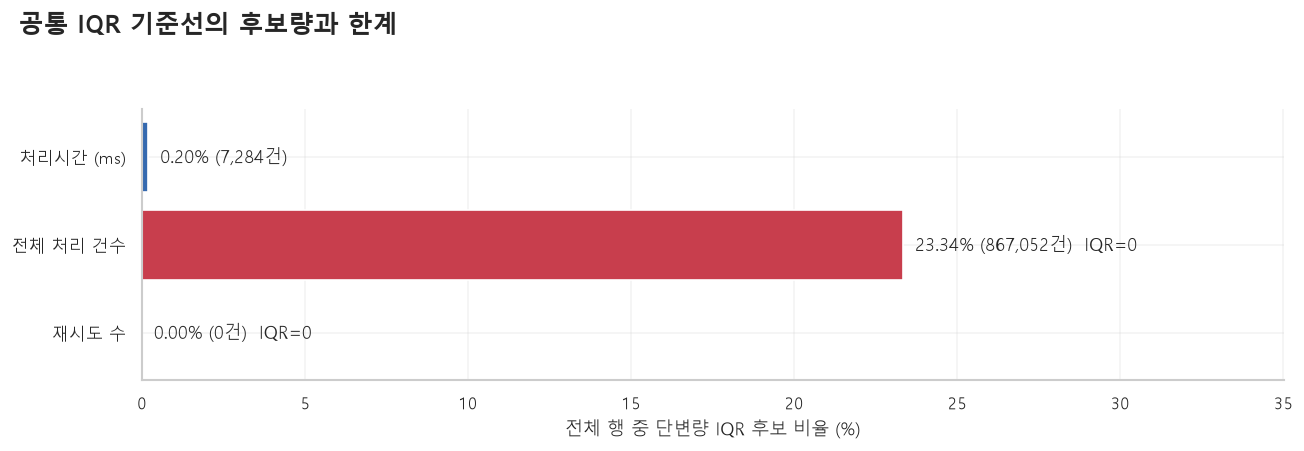

**실제 결과**

- IQR=0인 변수: totalCount, retryCount. 처리시간 외 카운트 변수는 정상 최빈값에서 벗어나기만 해도 후보가 될 수 있습니다.

**의미**: IQR=0이면 Q1과 Q3가 같아 정상 범위를 사실상 한 점으로 축소합니다. 이때 큰 후보량은 탐지 성능보다 혼합된 이산 분포와 기준선의 한계를 보여줍니다.

**모델 개발에 반영**: 전체 IQR 후보를 정답으로 학습하지 않습니다. 카운트는 업무별 허용값·범주형 표현을 검토하고 처리시간은 그룹별 기준선과 비교합니다.

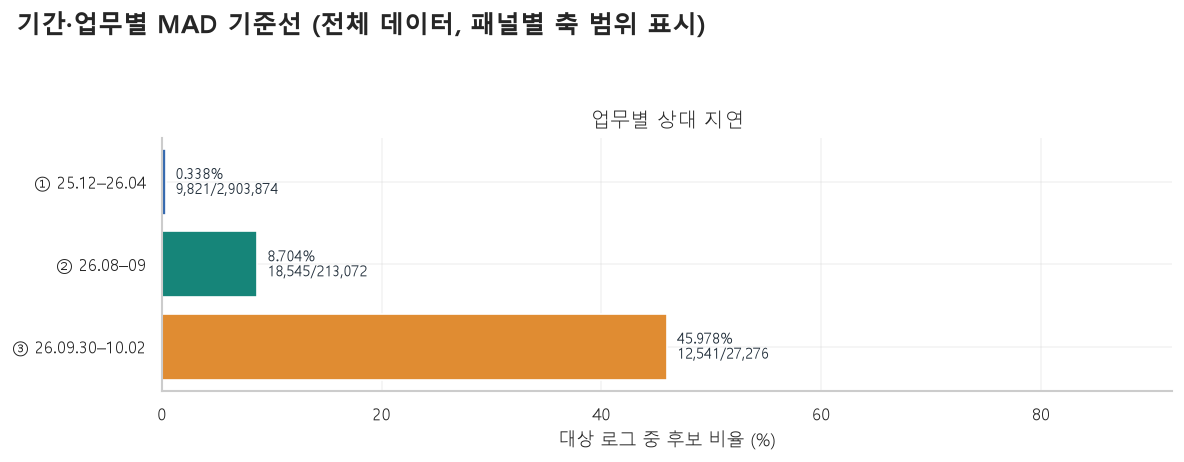

**실제 결과**

- ① 25.12–26.04 / 업무별 상대 지연: 9,821 / 2,903,874건 (0.338%).
- ② 26.08–09 / 업무별 상대 지연: 18,545 / 213,072건 (8.704%).
- ③ 26.09.30–10.02 / 업무별 상대 지연: 12,541 / 27,276건 (45.978%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- ① 25.12–26.04: 그룹 기준선으로 비교 불가 569,411건.
- ② 26.08–09: 그룹 기준선으로 비교 불가 437건.
- ③ 26.09.30–10.02: 그룹 기준선으로 비교 불가 129건.

**의미**: 업무별 상대 지연 후보가 많으면 그룹 내부 다중 모드 또는 매우 작은 MAD 때문에 규칙이 민감한지도 확인해야 합니다. MAD=0/표본 부족/처리시간 결측은 정상 0점이 아닙니다.

**모델 개발에 반영**: 그룹별 지연 분포를 다시 살피고 최소 분산·운영 허용 지연 등 기준선을 보완합니다. 이 전체기간 EDA 기준선은 시간 분리 모델의 입력에 사용하지 않습니다.

In [20]:
plot_statistical_candidates(df, iqr_table)


In [21]:
context_by_entity = df.groupby(["source_period", "processId"], observed=True).agg(
    rows=("transactionId", "size"), comparable=("context_comparable", "sum"), candidates=("context_candidate", "sum"))
context_by_entity["candidate_pct_of_comparable"] = context_by_entity["candidates"].div(
    context_by_entity["comparable"].replace(0, np.nan)).mul(100)
display(context_by_entity.loc[context_by_entity["comparable"].ge(30)].sort_values(
    "candidate_pct_of_comparable", ascending=False).head(20))
note("업무별 후보 비율의 분모는 전체 업무 행 수가 아니라 유효 처리시간·충분한 표본·MAD>0을 충족하는 비교 가능 행 수입니다.",
     "높은 비율은 지연 외에 업무 내부의 여러 실행 모드나 작은 MAD 때문에 발생할 수 있습니다.",
     "후보 비율 상위 업무를 먼저 검토하되 표본 수와 정상 실행 정의를 함께 확인합니다.")


rows  comparable  candidates  \
source_period     processId                                                   
26년9월30일-26년10월2일 IF_TEST_HA_FAILOVER_PR001   27047       27047       12530   
25년12월24일-26년4월6일 IF_FILE2FILE_000_PR001        110          52          17   
                  IF_FILE2FILE_000_PR002        108          48          13   
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001_PR001  84353       84298       17145   
25년12월24일-26년4월6일 SERVICE_DELAY_TEST_PR001     2255        2255         456   
26년9월30일-26년10월2일 IF_IBMMQ_SUB2DB_001_PR002      42          42           6   
25년12월24일-26년4월6일 IF_A2A_FILE_202_PR002          32          32           4   
                  IF_A2A_FILE_201_PR001          34          34           4   
                  IF_A2A_FILE_201_PR002          34          34           4   
                  HUG_UPDATE_TEST_001_PR001      39          37           4   
                  Handler_TEST_PR001             54          49           5   
                  IF_DB2DB_106_PR002            116         108          11   
26년9월30일-26년10월2일 IF_IBMMQ_SUB2DB_001_PR003      42          42           4   
25년12월24일-26년4월6일 IF_DB2DB_101_PR002            257         257          20   
                  IF_DB2DB_101_PR001            257         257          20   
                  IF_A2A_FILE_207_PR001          30          30           2   
                  HUG_DB_WRITER_TEST_PR001       48          47           3   
                  LOG_TEST_DEBUG_PR001         4211         208          11   
                  LOG_TEST_INFO_PR001          4080         114           6   
                  IF_AGENT2AGENT_001_PR001      820         814          42   

                                              candidate_pct_of_comparable  
source_period     processId                                                
26년9월30일-26년10월2일 IF_TEST_HA_FAILOVER_PR001                     46.326765  
25년12월24일-26년4월6일 IF_FILE2FILE_000_PR001                        32.692308  
                  IF_FILE2FILE_000_PR002                        27.083333  
26년8월15일-26년9월14일 IF_CLAUDE_CREATE_001_PR001                    20.338561  
25년12월24일-26년4월6일 SERVICE_DELAY_TEST_PR001                      20.221729  
26년9월30일-26년10월2일 IF_IBMMQ_SUB2DB_001_PR002                     14.285714  
25년12월24일-26년4월6일 IF_A2A_FILE_202_PR002                         12.500000  
                  IF_A2A_FILE_201_PR001                         11.764706  
                  IF_A2A_FILE_201_PR002                         11.764706  
                  HUG_UPDATE_TEST_001_PR001                     10.810811  
                  Handler_TEST_PR001                            10.204082  
                  IF_DB2DB_106_PR002                            10.185185  
26년9월30일-26년10월2일 IF_IBMMQ_SUB2DB_001_PR003                      9.523810  
25년12월24일-26년4월6일 IF_DB2DB_101_PR002                             7.782101  
                  IF_DB2DB_101_PR001                             7.782101  
                  IF_A2A_FILE_207_PR001                          6.666667  
                  HUG_DB_WRITER_TEST_PR001                       6.382979  
                  LOG_TEST_DEBUG_PR001                           5.288462  
                  LOG_TEST_INFO_PR001                            5.263158  
                  IF_AGENT2AGENT_001_PR001                       5.159705

**실제 결과**

- 업무별 후보 비율의 분모는 전체 업무 행 수가 아니라 유효 처리시간·충분한 표본·MAD>0을 충족하는 비교 가능 행 수입니다.

**의미**: 높은 비율은 지연 외에 업무 내부의 여러 실행 모드나 작은 MAD 때문에 발생할 수 있습니다.

**모델 개발에 반영**: 후보 비율 상위 업무를 먼저 검토하되 표본 수와 정상 실행 정의를 함께 확인합니다.

## 7. 처리 건수·재시도·상태 정합성

`totalCount = successCount + errorCount`는 세 값이 있는 경우만 검사합니다.
음수 건수, `S` 상태인데 오류 건수가 있는 경우도 점검 후보로 확인합니다.
`F` 상태의 오류 건수 0은 실행 전에 실패했을 수 있어 모순으로 단정하지 않습니다.

,rows,count_comparable,count_mismatches,negative_counts,success_with_errors
source_period,,,,,
25년12월24일-26년4월6일,3473285,3473280,823,0,10
26년8월15일-26년9월14일,213509,213509,0,0,0
26년9월30일-26년10월2일,27405,27405,0,0,0


source_period      retryCount
25년12월24일-26년4월6일  0.0           3473285
26년8월15일-26년9월14일  0.0            213509
26년9월30일-26년10월2일  0.0             27405
Name: execution_rows, dtype: int64

,logical_processes,execution_rows,max_attempts
source_period,,,
25년12월24일-26년4월6일,3473285,3473285,1
26년8월15일-26년9월14일,213509,213509,1
26년9월30일-26년10월2일,27405,27405,1


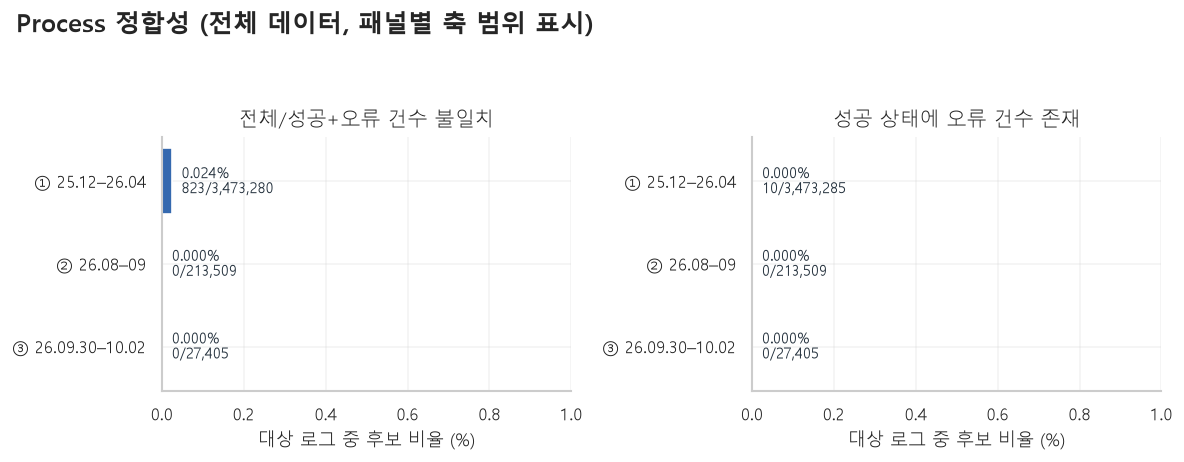

**실제 결과**

- ① 25.12–26.04 / 전체/성공+오류 건수 불일치: 823 / 3,473,280건 (0.024%).
- ② 26.08–09 / 전체/성공+오류 건수 불일치: 0 / 213,509건 (0.000%).
- ③ 26.09.30–10.02 / 전체/성공+오류 건수 불일치: 0 / 27,405건 (0.000%).
- ① 25.12–26.04 / 성공 상태에 오류 건수 존재: 10 / 3,473,285건 (0.000%).
- ② 26.08–09 / 성공 상태에 오류 건수 존재: 0 / 213,509건 (0.000%).
- ③ 26.09.30–10.02 / 성공 상태에 오류 건수 존재: 0 / 27,405건 (0.000%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 재시도 값 종류 1개; 논리 Process당 최대 실행 행 1건.

**의미**: 재시도 수가 모두 0이면 현재 수집 데이터에서 재시도 행동을 학습할 수 없습니다. 처리 건수 일치 여부는 완료 상태/어댑터의 계수 정의와 대조해야 합니다.

**모델 개발에 반영**: 현재 상수 재시도 피처의 변별력은 없고, 향후 비영(0이 아닌) 값 출현을 별도로 감시합니다.

In [22]:
df["count_comparable"] = df[["totalCount", "successCount", "errorCount"]].notna().all(axis=1)
df["count_diff"] = df["totalCount"] - df["successCount"] - df["errorCount"]
df["count_mismatch_candidate"] = df["count_comparable"] & df["count_diff"].ne(0)
df["negative_count"] = df[["totalCount", "successCount", "errorCount", "retryCount"]].lt(0).any(axis=1)
df["success_with_errors"] = df["status"].eq("S") & df["errorCount"].gt(0)
df["integrity_candidate"] = df["count_mismatch_candidate"] | df["negative_count"] | df["negative_duration"] | df["success_with_errors"]
display(df.groupby("source_period", observed=True).agg(
    rows=("processId", "size"), count_comparable=("count_comparable", "sum"),
    count_mismatches=("count_mismatch_candidate", "sum"), negative_counts=("negative_count", "sum"),
    success_with_errors=("success_with_errors", "sum")))
retry_summary = df.groupby(["source_period", "retryCount"], observed=True).size().rename("execution_rows")
display(retry_summary)
attempt_counts = df.loc[df["transactionId"].notna() & df["processId"].notna()].groupby(
    ["source_period", "transactionId", "processId"], observed=True).size()
display(attempt_counts.groupby(level="source_period").agg(logical_processes="size", execution_rows="sum", max_attempts="max"))
plot_rule_rates(df, {"count_mismatch_candidate": "전체/성공+오류 건수 불일치", "success_with_errors": "성공 상태에 오류 건수 존재"},
                {"count_mismatch_candidate": "count_comparable"}, "Process 정합성")
note(f"재시도 값 종류 {df['retryCount'].dropna().nunique():,}개; 논리 Process당 최대 실행 행 {attempt_counts.max():,}건.",
     "재시도 수가 모두 0이면 현재 수집 데이터에서 재시도 행동을 학습할 수 없습니다. 처리 건수 일치 여부는 완료 상태/어댑터의 계수 정의와 대조해야 합니다.",
     "현재 상수 재시도 피처의 변별력은 없고, 향후 비영(0이 아닌) 값 출현을 별도로 감시합니다.")


## 8. 선행 프로세스의 존재·시간 겹침·재시도 모호성

선행 프로세스는 **같은 기간·같은 거래** 안에서 찾습니다.
선행 로그 존재와 종료시각 결측을 구분하며, 선행 실행이 여러 개면 재시도 연결이
모호하므로 시간 비교에서 제외합니다. 음수 의존 간격은 비동기·스트리밍 업무에서
정상일 수 있어 단순 순서 위반이나 확정 이상으로 판정하지 않습니다.
다른 거래에서 템플릿 ID가 발견되는 경우는 동일 실행의 선행 로그를 찾았다는 뜻이 아닙니다.

,has_predecessor,parent_log_found,dependency_missing,dependency_retry_ambiguous,dependency_time_comparable,dependency_overlap_candidate,template_only_elsewhere
source_period,,,,,,,
25년12월24일-26년4월6일,1713241,1708072,5169,0,1450157,104961,5169
26년8월15일-26년9월14일,152,152,0,0,139,127,0
26년9월30일-26년10월2일,147,147,0,0,147,147,0


,count,mean,std,min,1%,50%,95%,99%,max
source_period,,,,,,,,,
25년12월24일-26년4월6일,1450157.0,3.661,623.396,-89046.0,-4.00,16.0,47.0,73.00,3732.0
26년8월15일-26년9월14일,139.0,-705.475,3801.636,-23049.0,-22503.82,-4.0,2.0,36.28,66.0
26년9월30일-26년10월2일,147.0,-4.810,2.880,-24.0,-18.78,-4.0,-3.0,-2.00,-2.0


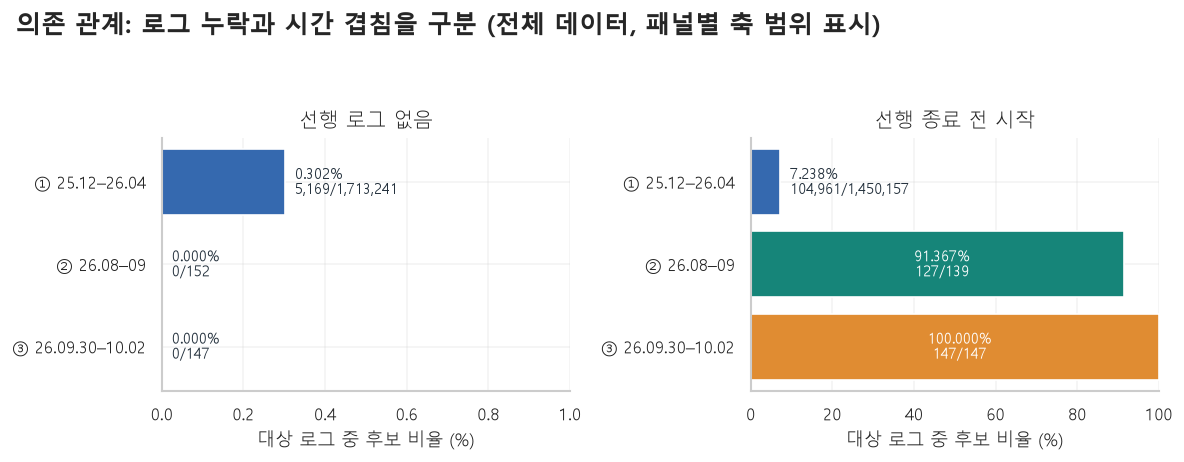

**실제 결과**

- ① 25.12–26.04 / 선행 로그 없음: 5,169 / 1,713,241건 (0.302%).
- ② 26.08–09 / 선행 로그 없음: 0 / 152건 (0.000%).
- ③ 26.09.30–10.02 / 선행 로그 없음: 0 / 147건 (0.000%).
- ① 25.12–26.04 / 선행 종료 전 시작: 104,961 / 1,450,157건 (7.238%).
- ② 26.08–09 / 선행 종료 전 시작: 127 / 139건 (91.367%).
- ③ 26.09.30–10.02 / 선행 종료 전 시작: 147 / 147건 (100.000%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 선행 관계 1,713,540건 중 시간 비교 가능 1,450,443건. 선행 로그 없음 5,169건; 시간 겹침 105,235건.

**의미**: 선행 로그 존재와 선행 종료시각 유무는 다른 조건입니다. 시간 겹침은 비동기·스트리밍 실행에서 정상일 수 있으므로 의존 순서 위반으로 단정하지 않습니다.

**모델 개발에 반영**: 선행 로그 누락, 재시도 연결 모호성, 시간 겹침을 별도 피처로 관리하고 업무별 동기/비동기 실행 정의와 비교합니다.

In [23]:
dependency = dependency_features(df)
df[dependency.columns] = dependency
dependency_flags = ["has_predecessor", "parent_log_found", "dependency_missing",
                    "dependency_retry_ambiguous", "dependency_time_comparable",
                    "dependency_overlap_candidate", "template_only_elsewhere"]
display(df[dependency_flags].groupby(df["source_period"], observed=True).sum())
display(df.groupby("source_period", observed=True)["dependency_gap_ms"].describe(percentiles=[.01, .5, .95, .99]).round(3))
plot_dependency(df)


In [ ]:
dependency_by_adapter = df.groupby(["source_period", "adapterType"], observed=True).agg(
    rows=("processId", "size"), missing_parent=("dependency_missing", "sum"),
    timing_comparable=("dependency_time_comparable", "sum"), overlap_candidates=("dependency_overlap_candidate", "sum"))
dependency_by_adapter["overlap_pct_of_comparable"] = dependency_by_adapter["overlap_candidates"].div(
    dependency_by_adapter["timing_comparable"].replace(0, np.nan)).mul(100)
display(dependency_by_adapter.round(3))
display(df.loc[df["dependency_missing"] | df["dependency_overlap_candidate"],
               ["source_period", "transactionId", "processId", "dependProcessId", "adapterType", "dependency_gap_ms"]].head(20))
note("어댑터별 시간 겹침 비율은 선행 로그가 존재하고 재시도가 모호하지 않으며 양쪽 시각이 있는 실행만 분모로 삼습니다.",
     "시간 겹침이 특정 어댑터에 집중되면 동기/비동기 실행 방식의 정상 특성일 수도 있습니다.",
     "선행 관계를 해석할 때 템플릿 ID가 아닌 같은 거래의 실행 키를 사용합니다.")


## 9. 기간별 분포 변화와 새로운 범주

첫 기간을 기준으로 수치형 PSI와 새로운 업무·경로 비율을 비교합니다.
PSI는 기준 기간의 고정 분위수 구간을 사용하며 0에 가까울수록 분포가 유사합니다.
기준 기간의 범위를 벗어난 값과 상수였던 변수의 새 값도 별도 구간에 집계합니다.
구간 수와 관측 행 수도 함께 확인하며 분위수와 결측률을 같이 비교합니다.
기간 차이는 운영 환경·업무·수집 범위 변화일 수 있어 이상으로 바로 확정하지 않습니다.

,feature,source_period,reference_rows,current_nonmissing,bins,PSI,median,p99,missing_pct
0,duration_ms,25년12월24일-26년4월6일,2905838,2905838,12,0.0000,989.5,9682.00,16.3375
1,duration_ms,26년8월15일-26년9월14일,2905838,213373,12,7.6573,31.0,179.00,0.0637
2,duration_ms,26년9월30일-26년10월2일,2905838,27405,12,4.2771,5969.0,45547.76,0.0000
3,totalCount,25년12월24일-26년4월6일,3473280,3473280,4,0.0000,10000.0,10485760.00,0.0001
4,totalCount,26년8월15일-26년9월14일,3473280,213509,4,9.4637,1.0,1.00,0.0000
5,totalCount,26년9월30일-26년10월2일,3473280,27405,4,10.4360,1.0,1.00,0.0000
6,retryCount,25년12월24일-26년4월6일,3473285,3473285,3,0.0000,0.0,0.00,0.0000
7,retryCount,26년8월15일-26년9월14일,3473285,213509,3,0.0000,0.0,0.00,0.0000
8,retryCount,26년9월30일-26년10월2일,3473285,27405,3,0.0002,0.0,0.00,0.0000


,feature,source_period,unique_values,new_values,new_value_row_pct
0,processId,25년12월24일-26년4월6일,614,0,0.000
1,processId,26년8월15일-26년9월14일,88,52,99.945
2,processId,26년9월30일-26년10월2일,26,21,99.756
3,adapterType,25년12월24일-26년4월6일,23,0,0.000
4,adapterType,26년8월15일-26년9월14일,15,0,0.000
5,adapterType,26년9월30일-26년10월2일,13,1,0.011
6,flow_key,25년12월24일-26년4월6일,63,0,0.000
7,flow_key,26년8월15일-26년9월14일,33,4,0.004
8,flow_key,26년9월30일-26년10월2일,16,1,0.011


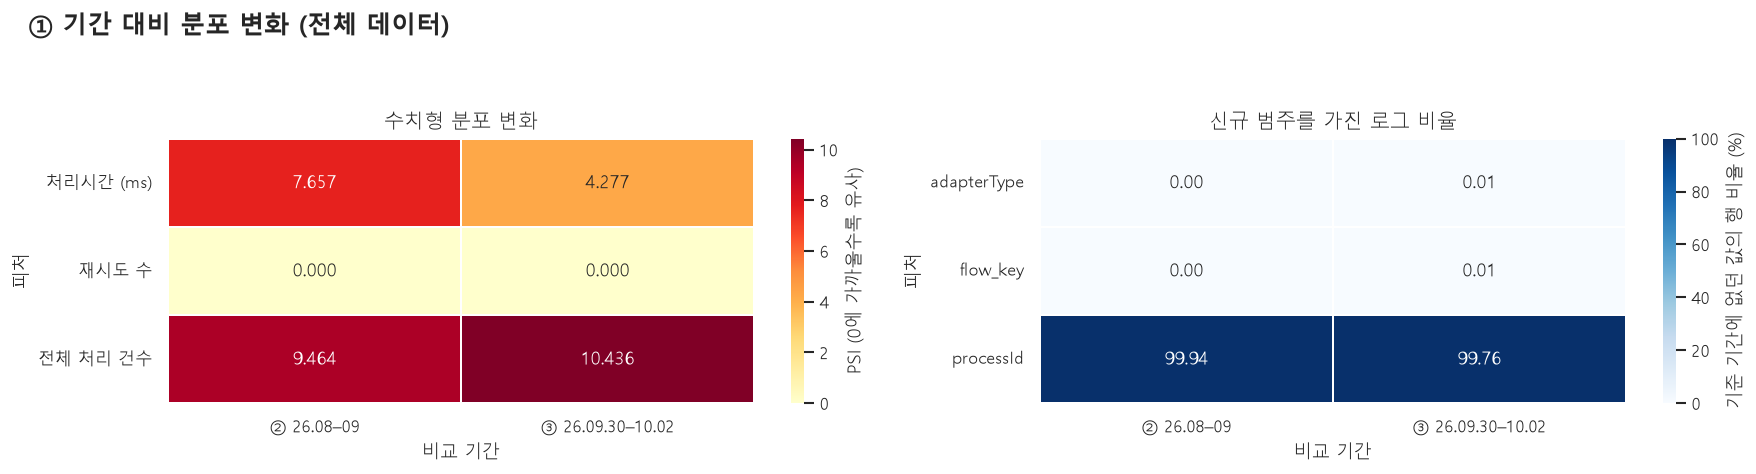

**실제 결과**

- ③ 26.09.30–10.02 / 전체 처리 건수: PSI 10.436.
- ② 26.08–09 / 전체 처리 건수: PSI 9.464.
- ② 26.08–09 / 처리시간 (ms): PSI 7.657.
- ② 26.08–09 / processId: 기준 기간에 없던 값을 가진 로그 99.94%.

**의미**: 여러 피처와 업무 ID가 함께 바뀌면 처리 방식·업무 구성·수집 범위 변화(도메인 변화)를 우선 의심합니다. PSI는 분포 차이 지표이며 실제 이상 비율이 아닙니다. 상수 피처의 극소 PSI는 표본 크기와 평활화 때문일 수 있습니다.

**모델 개발에 반영**: 전체 기간 공통 모델과 업무/운영 환경별 기준 모델을 비교합니다. 새 범주 로그는 지연·정합성 증거를 함께 검토하며 신규 업무라는 이유만으로 장애로 확정하지 않습니다.

In [25]:
drift_numeric = numeric_drift(df, ['duration_ms', 'totalCount', 'retryCount'])
drift_categories = categorical_drift(df, ['processId', 'adapterType', 'flow_key'])
display(drift_numeric.round(4))
display(drift_categories.round(3))
plot_drift(drift_numeric, drift_categories)


### 9.1 수치 피처 간 중복 정보

긴 꼬리에 강한 Spearman 상관계수를 기간별 균형 표본에서 확인합니다.
강한 상관관계나 전부 결측·상수인 피처는 모델 입력을 검토할 때 참고합니다.

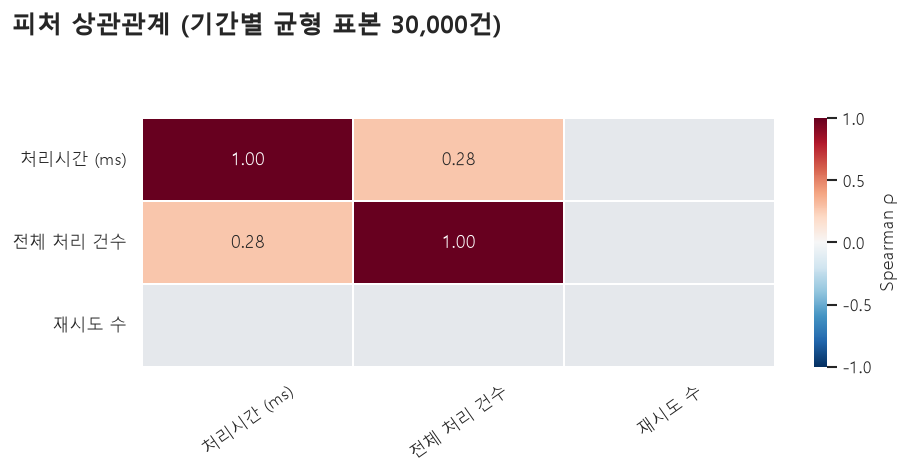

**실제 결과**

- 가장 강한 관계: duration_ms–totalCount, ρ=0.279.
- 상수/유효값 부족으로 상관 계산 불가: retryCount.

**의미**: 회색/빈 칸은 상관 0이 아니라 계산 불가입니다. 통합 표본의 상관은 기간 간 차이 때문에 커질 수도 있어 인과관계나 그룹 내부 관계로 바로 해석하지 않습니다.

**모델 개발에 반영**: 중복 피처를 줄이고 기간/업무별 상관도 대조합니다. 상수 피처 제거와 데이터 단위 확인 후 모델 입력을 결정합니다.

In [26]:
corr_sample = sample_by_period(df, PLOT_SAMPLE, RANDOM_STATE)
plot_correlation(corr_sample, ['duration_ms', 'totalCount', 'retryCount'])


## 10. 시간 순서 검증을 갖춘 비지도 기준 모델

Isolation Forest에 처리시간·로그 건수·재시도·순환 시간 피처·업무 범주 빈도를
입력합니다. 거래 ID와 데이터 기간은 입력에서 제외하고, `status`, `responseCode`,
성공/오류 건수와 정합성 후보는 사후 해석에만 사용합니다.

관측 날짜 순서로 약 60%/20%/20%를 학습/검증/시험으로 나눕니다.
같은 거래의 로그는 같은 분할에 두고, 분할 경계를 넘는 거래는 평가에서 제외합니다.
결측 대치·스케일링·범주 빈도는 학습 구간에서만 정합니다.
전체 학습 구간의 범주 빈도를 사용하되 모델 학습은 최대 10만 행,
점수 산출은 10만 행씩 처리해 메모리를 제한합니다.

임계값은 검증 점수의 99% 분위수입니다. 이는 검토량을 정하는 운영 설정이며
실제 이상 비율 추정치가 아닙니다. 시험 데이터에는 고정한 임계값을 적용합니다.
정답 라벨이 없으므로 accuracy/F1/precision으로 성능을 주장하지 않습니다.

In [27]:
MODEL_NUMERIC = ['duration_ms', 'totalCount', 'retryCount']
MODEL_CATEGORICAL = ['processId', 'adapterType', 'channelId', 'flow_key']
model_result, model_profile, fitted = fit_anomaly_baseline(
    df, MODEL_NUMERIC, MODEL_CATEGORICAL, max_train=MAX_TRAIN_ROWS,
    batch_size=SCORE_BATCH_ROWS, alert_quantile=ALERT_QUANTILE, random_state=RANDOM_STATE)
display(pd.DataFrame([{k: v for k, v in model_profile.items() if k != "features"}]).T.rename(columns={0: "값"}))
display(baseline_report(df, model_result))
split_times = df[["source_period", "startTime"]].assign(split=model_result["split"]).groupby(
    ["source_period", "split"], observed=True).agg(rows=("startTime", "size"), first=("startTime", "min"), last=("startTime", "max"))
display(split_times)
note(f"학습 전체 {model_profile['training_rows']:,}건, 실제 모델 학습 표본 {model_profile['training_sample_rows']:,}건; "
     f"검증 {model_profile['validation_rows']:,}건, 시험 {model_profile['test_rows']:,}건.",
     "날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.",
     "시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.")


,값
training_rows,3.175652e+06
training_sample_rows,1.000000e+05
validation_rows,4.266690e+05
test_rows,1.115490e+05
feature_count,1.700000e+01
validation_quantile,9.900000e-01
threshold,7.332487e-01


rows  scored_rows  \
source_period     split                                                 
25년12월24일-26년4월6일 excluded_boundary_transaction        4            0   
                  excluded_missing_time_or_id        312            0   
                  train                          3175652      3175652   
                  validation                      297317       297317   
26년8월15일-26년9월14일 excluded_missing_time_or_id         13            0   
                  test                             84144        84144   
                  validation                      129352       129352   
26년9월30일-26년10월2일 test                             27405        27405   

                                                 mean_score  candidates  \
source_period     split                                                   
25년12월24일-26년4월6일 excluded_boundary_transaction         NaN           0   
                  excluded_missing_time_or_id           NaN           0   
                  train                              0.5049          64   
                  validation                         0.5443        1656   
26년8월15일-26년9월14일 excluded_missing_time_or_id           NaN           0   
                  test                               0.7126        1796   
                  validation                         0.7158        4242   
26년9월30일-26년10월2일 test                               0.6742           2   

                                                 candidate_pct  
source_period     split                                         
25년12월24일-26년4월6일 excluded_boundary_transaction         0.0000  
                  excluded_missing_time_or_id           0.0000  
                  train                                 0.0020  
                  validation                            0.5570  
26년8월15일-26년9월14일 excluded_missing_time_or_id           0.0000  
                  test                                  2.1344  
                  validation                            3.2794  
26년9월30일-26년10월2일 test                                  0.0073

rows  \
source_period     split                                    
25년12월24일-26년4월6일 excluded_boundary_transaction        4   
                  excluded_missing_time_or_id        312   
                  train                          3175652   
                  validation                      297317   
26년8월15일-26년9월14일 excluded_missing_time_or_id         13   
                  test                             84144   
                  validation                      129352   
26년9월30일-26년10월2일 test                             27405   

                                                                  first  \
source_period     split                                                   
25년12월24일-26년4월6일 excluded_boundary_transaction 2026-01-12 10:28:56.989   
                  excluded_missing_time_or_id                       NaT   
                  train                         2025-12-24 10:25:31.689   
                  validation                    2026-03-23 08:12:59.703   
26년8월15일-26년9월14일 excluded_missing_time_or_id                       NaT   
                  test                          2026-08-20 00:00:00.295   
                  validation                    2026-08-15 00:00:00.284   
26년9월30일-26년10월2일 test                          2026-09-30 09:49:26.494   

                                                                   last  
source_period     split                                                  
25년12월24일-26년4월6일 excluded_boundary_transaction 2026-04-02 11:14:00.511  
                  excluded_missing_time_or_id                       NaT  
                  train                         2026-03-20 17:04:27.315  
                  validation                    2026-04-06 08:51:33.531  
26년8월15일-26년9월14일 excluded_missing_time_or_id                       NaT  
                  test                          2026-09-14 14:19:59.710  
                  validation                    2026-08-19 23:59:55.042  
26년9월30일-26년10월2일 test                          2026-10-02 15:36:59.559

**실제 결과**

- 학습 전체 3,175,652건, 실제 모델 학습 표본 100,000건; 검증 426,669건, 시험 111,549건.

**의미**: 날짜 단위 약 60/20/20 분할이므로 행 수의 비율이 60/20/20일 필요는 없습니다. 학습 기간에 없던 업무 구성은 시험 시 분포 변화로 나타날 수 있습니다.

**모델 개발에 반영**: 시간 분리와 거래 단위 그룹을 유지하고, 기준 모델의 경보량을 업무별 모델과 비교합니다.

### 10.1 시험 구간의 점수와 검토 후보

후보 비율과 상위 점수를 기간별로 확인합니다. 새로운 기간의 대량 경보는
실제 장애뿐 아니라 분포 변화나 로그 수집 차이 때문일 수 있습니다.
상태·정합성 규칙과의 교차표는 해석을 돕는 참고값으로만 봅니다.

In [ ]:
top_index = model_result.loc[model_result["split"].eq("test") & model_result["anomaly_candidate"]].nlargest(20, "anomaly_score").index
display(df.loc[top_index, ['source_period', 'transactionId', 'processId', 'startTime', 'adapterType', 'status', 'responseCode', 'duration_ms', 'totalCount', 'retryCount', 'dependency_gap_ms', 'context_z']].join(model_result[["anomaly_score"]]))


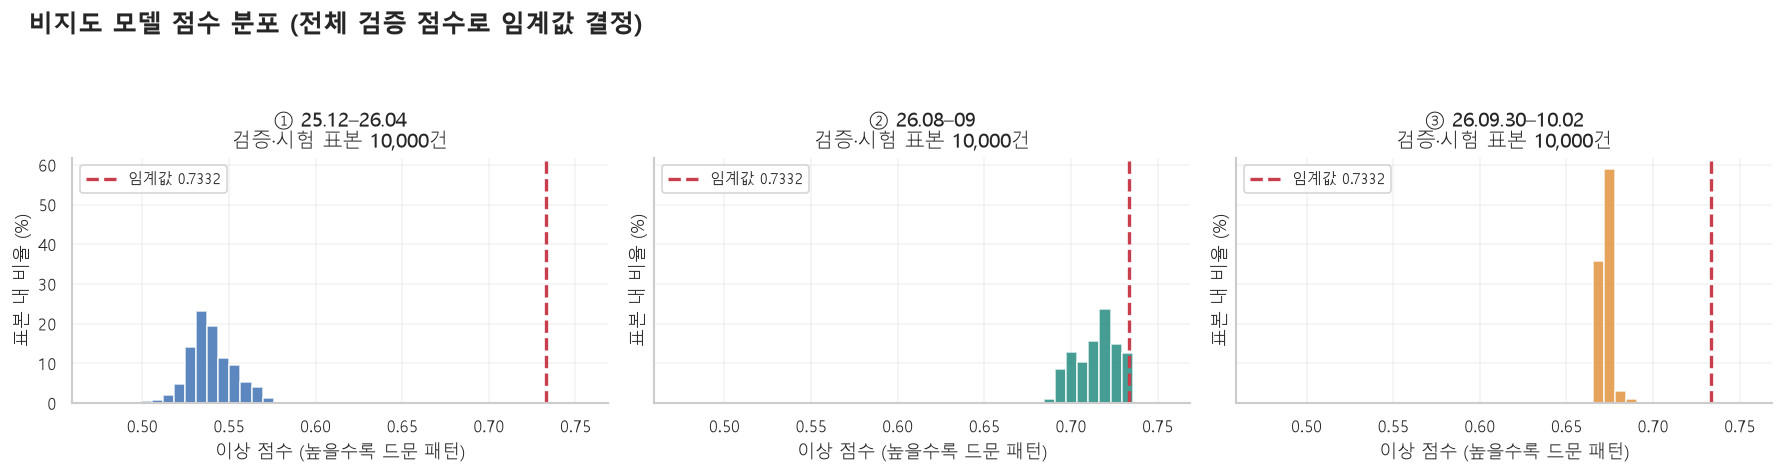

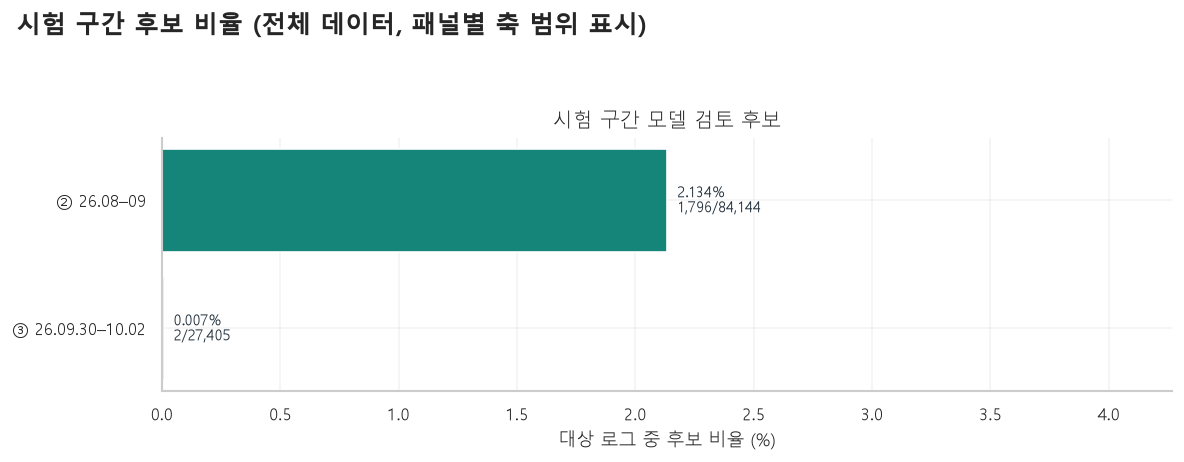

**실제 결과**

- ② 26.08–09 / 시험 구간 모델 검토 후보: 1,796 / 84,144건 (2.134%).
- ③ 26.09.30–10.02 / 시험 구간 모델 검토 후보: 2 / 27,405건 (0.007%).

**의미**: 분모는 각 규칙의 비교 가능한 로그입니다(별도 조건이 없는 규칙은 기간 전체 행). 서로 다른 규칙의 후보는 중복될 수 있어 합산하면 안 됩니다. 후보 0건과 비교 불가는 다릅니다.

**모델 개발에 반영**: 낮은 비율도 실제 건수로 확인해 검토 대상을 정합니다. 정합성 규칙은 비지도 모델 점수와 별도로 표시하며 확정 장애 라벨로 사용하지 않습니다.

**실제 결과**

- 시험 전체 111,549건 중 후보 1,798건 (1.61%). 임계값 0.7332; 검증 점수의 99% 분위수입니다.

**의미**: 히스토그램은 표본이지만 시험 후보율은 전체 시험 로그로 계산했습니다. 99% 검증 분위수를 적용해도 기간 변화와 점수 동률 때문에 시험 후보율이 1%일 필요는 없습니다.

**모델 개발에 반영**: 이 비율은 정확도가 아니라 사람이 검토할 양입니다. 상태·업무·수집 변화와 후보를 교차 검토하고 실제 장애 확인 표본으로 precision/recall을 평가합니다.

In [29]:
plot_model_scores(df, model_result, model_profile)


### 10.2 후보의 상태·정합성은 사후 해석입니다

후보/비후보 각각을 100%로 맞춘 교차표입니다. `status=F`를 정답으로 둔
학습·평가가 아니므로 실패 상태가 많은 것을 precision으로 해석하지 않습니다.

In [30]:
test_view = df.loc[model_result["split"].eq("test"), ["status", 'integrity_candidate']].join(model_result[["anomaly_candidate"]])
display(pd.crosstab(test_view["anomaly_candidate"], text(test_view["status"]), normalize="index").mul(100).round(2))
display(pd.crosstab(test_view["anomaly_candidate"], test_view['integrity_candidate'], normalize="index").mul(100).round(2))
note("위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.",
     "후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.",
     "상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.")
del test_view


status,F,H,N,S,Z
anomaly_candidate,,,,,
False,66.23,0.0,0.07,33.61,0.09
True,94.38,0.0,0.00,5.62,0.00


integrity_candidate,False
anomaly_candidate,
False,100.0
True,100.0


**실제 결과**

- 위 표의 각 행은 후보 또는 비후보 집단 내부의 상태/정합성 비율입니다. 두 집단의 건수는 서로 다릅니다.

**의미**: 후보는 희귀한 행동 패턴입니다. 실패 상태·정합성 후보와 겹칠 수 있지만 같지 않으며, 성공 상태의 후보도 검토 대상입니다.

**모델 개발에 반영**: 상위 점수와 상태·업무·지연 근거를 함께 검토해 실제 이상 라벨을 확보합니다.

### 10.3 PCA로 보는 피처 공간

PCA는 학습 데이터에만 맞추고 기간별 균형 표본을 투영합니다.
그림은 구조를 살펴보는 2차원 요약이며 분리되어 보인다는 사실만으로 이상을 확정하지 않습니다.

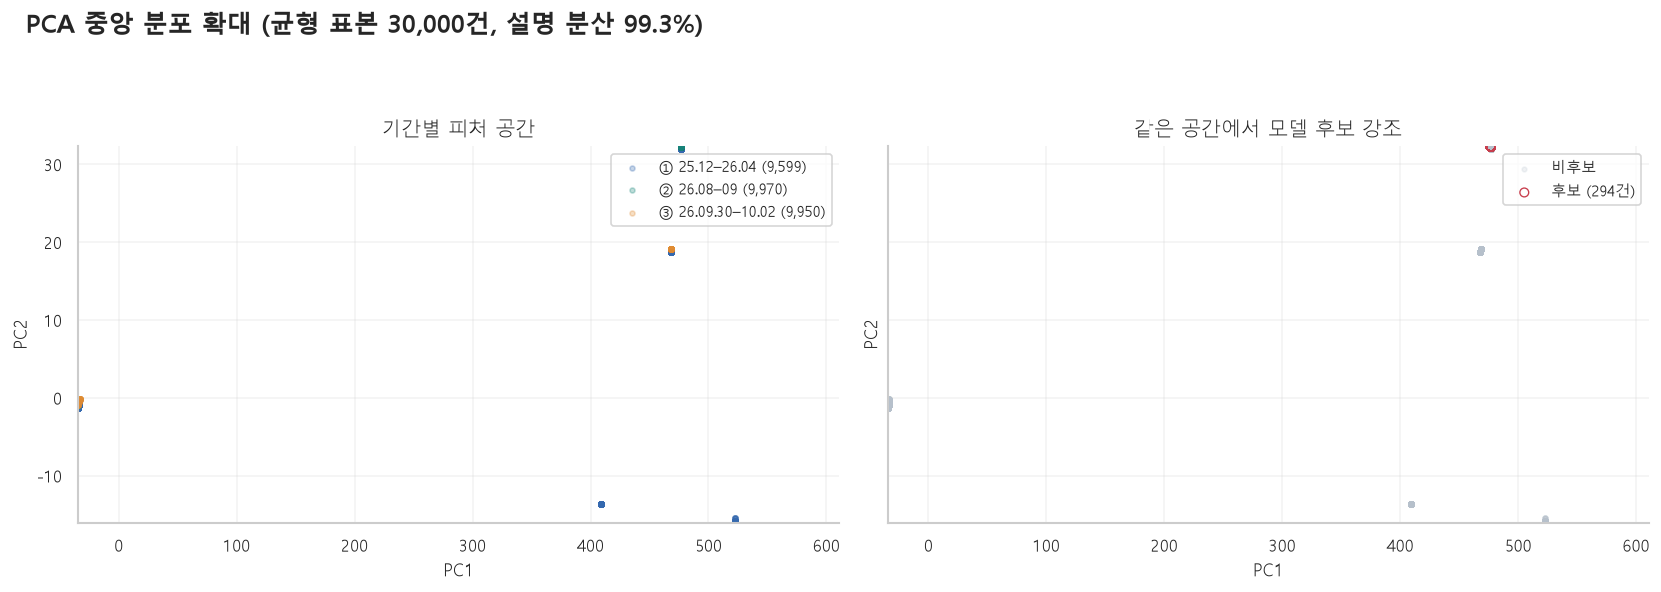

**실제 결과**

- 각 축의 표본 0.5–99.5% 범위를 확대했습니다. 화면 밖 481건 중 후보 6건은 모델 계산에서 제외하지 않았습니다. 전체 투영 표본 후보 300건.

**의미**: 왼쪽은 기간 차이, 오른쪽은 후보의 위치를 보여줍니다. PCA 2축은 전체 피처 정보의 일부만 보존하므로 떨어진 군집이나 점 하나를 실제 이상으로 확정할 수 없습니다.

**모델 개발에 반영**: 분리된 기간은 도메인 변화의 단서로 보고 원래 피처와 업무 종류를 확인합니다. 화면 밖 후보도 상위 점수 표로 함께 검토합니다.

0         log_duration_ms
1     missing_duration_ms
2          log_totalCount
3      missing_totalCount
4      missing_retryCount
5                hour_sin
6                hour_cos
7             weekday_sin
8             weekday_cos
9        rarity_processId
10       unseen_processId
11     rarity_adapterType
12     unseen_adapterType
13       rarity_channelId
14       unseen_channelId
15        rarity_flow_key
16        unseen_flow_key
Name: model_input_feature, dtype: str

In [31]:
from sklearn.decomposition import PCA

pca = PCA(n_components=2, random_state=RANDOM_STATE).fit(fitted["X_train"])
pca_sample = sample_by_period(df.loc[model_result["anomaly_score"].notna()], PLOT_SAMPLE, RANDOM_STATE)
coords = pca.transform(fitted["transform"](pca_sample))
projection = pd.DataFrame(coords, columns=["PC1", "PC2"], index=pca_sample.index)
projection["source_period"] = pca_sample["source_period"]
projection["candidate"] = model_result.loc[pca_sample.index, "anomaly_candidate"]
plot_projection(projection, pca.explained_variance_ratio_.sum())
display(pd.Series(model_profile["features"], name="model_input_feature"))


## 11. 모델 개발로 이어지는 해석

- 통합 분포와 기간별 변화가 크면 업무 그룹 기준선과 운영 환경별 모델을 비교합니다.
- 처리시간의 긴 꼬리에는 로그 변환을, 시간 주기에는 sin/cos 표현을 사용합니다.
- 거래 ID는 결합 키이며 모델 입력에서 제외합니다. 업무 ID는 범주 빈도나 별도 표현을 검토합니다.
- 결측·재시도·수집 범위가 만든 후보와 실제 실행 이상 후보를 사람 검토로 구분합니다.
- 실제 성능 평가는 검토로 확정된 표본이나 통제된 장애 주입 데이터가 필요합니다.
- 이후 비교 모델은 LOF/강건 공분산/Autoencoder 및 시계열 예측 잔차 모델로 확장할 수 있습니다.
  모든 대치·변환·기준선·임계값은 학습/검증 단계에서만 결정합니다.